# Three-station BiLSTM: 72 h SWC_20 forecast at FD11, CB25 and FD02

This notebook does the whole three-station study in one run. One BiLSTM is trained on FD11, CB25 and FD02 together, using 2015–2021 for training, 2022 for validation and 2024 for testing; 2023 is skipped because FD11's rain gauge recorded nothing for most of that year. The target is `SWC_20` exactly 72 hours after the last hour of a 48-hour input window.

It has three parts that run one after the other:

1. Feature tests (sections 8–10): which inputs to add, swap or drop, compared with the 7 inputs of combined_10yr. 18 runs on every 5th training window, about an hour.
2. Loss tests (sections 11–13): Huber with δ = 0.005, 0.01 and 0.02 and MSE, using the inputs chosen in part 1. 8 runs, about 25 minutes.
3. Final model (sections 14–21): the previous and new setups on every training window, one grid search over the BiLSTM size, the tuned model, and its evaluation, including CB06 and CB04, two stations never used for training. About 1.5 to 2 hours.

The whole notebook takes about 3 to 3.5 hours on a Colab T4 GPU.

How to run it on Colab:

1. Open colab.research.google.com, then File > Upload notebook and pick this file.
2. Runtime > Change runtime type > T4 GPU.
3. The data file `TxSON33_modeling_complete.parquet` is read from the Files panel (`/content`). If it is not there, the data cell downloads it from GitHub into the Files panel, which takes a few seconds.
4. Runtime > Run all. The setup cell asks for access to Google Drive; allow it. Keep the browser tab open while it runs.
5. When the last cell has run, File > Download > Download .ipynb, so the outputs are kept.

Checkpoints go to one Google Drive folder, `MyDrive/three_stations_72h`: `runs/` holds one file per finished run (weights, forecasts, loss history), `choices.json` the chosen `FEATURES`, `LOSS` and grid size, and the `.csv` files the result tables. If the runtime disconnects, reconnect and use Runtime > Run all again. Finished runs are loaded from Drive in a few seconds, so only the run that was training at the time of the disconnect is lost, and the notebook ends with the same choices and tables. To start fresh, delete the Drive folder (or set `SAVE_DIR` to a new folder).

The inputs tested in this notebook. The last two depend only on the date and are worked out from the 2015–2021 data.

| Feature | What it is | Why it might help |
|---|---|---|
| SWC_20 | soil water at 20 cm now | the forecast starts from this value |
| SWC_5 | soil water at 5 cm | it reacts to rain first, so it shows water that may still reach 20 cm |
| Ppt_sum_log_24h | log1p of the rain in the last 24 h | recent rain may still be soaking down |
| T_5_mean_24h | mean soil temperature at 5 cm over the last 24 h | warm soil loses water faster to evaporation and plants |
| doy_sin, doy_cos | day of year as a point on a circle | drying speed and rain change through the year; 31 Dec and 1 Jan end up close together |
| SWC_20_below_max_72h | SWC_20 minus its highest value in the last 72 h (always ≤ 0) | how much it is drying out: 0 = at its recent peak (it just rained or is still rising), slightly negative = it has started drying, very negative = it has been drying for days and is far below its peak |
| SWC_20_below_max_24h, _168h | the same over 24 h or 168 h | tests which memory length works best |
| SWC_5_minus_SWC_20 | SWC_5 − SWC_20 | positive = the top soil is wetter, so water is still moving down and SWC_20 is likely to rise; if it stays low after rain, the rain did not soak in far |
| SWC_50 | soil water at 50 cm | wet deep soil slows how fast 20 cm drains |
| season | 4 columns (winter Dec–Feb, spring Mar–May, summer Jun–Aug, fall Sep–Nov), one set to 1 | a coarser version of the date |
| SWC_20_minus_normal | SWC_20 minus this station's usual SWC_20 for this date | wetter or drier than usual for the time of year; the soil tends to drift back toward its normal level |
| rain_chance_72h | how often the training years had 2 mm or more of rain in the next 72 h around this date | the only input about rain that might fall during the forecast gap; it depends only on the date, so it is known ahead of time |

## 1. Setup

Imports, the data file location, the checkpoint folder and the settings used everywhere: stations, years, window length, horizon and training settings. `SAVE_DIR` is the Google Drive folder for the checkpoints; Drive is mounted here, and the printout says how many finished runs are already saved there.

In [5]:
# --- Setup ---
import hashlib
import json
import os
import random
import re
import time
import urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import MinMaxScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)
pd.set_option("display.max_rows", 500)       # long result tables are shown in full
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 250)

# The data file. On Colab it is read from the Files panel (/content); in the repo it is one folder up. If it is in
# neither place, the data cell downloads it from GitHub into the current folder (the Files panel on Colab).
PARQUET_NAME = "TxSON33_modeling_complete.parquet"
PARQUET_PATH = next((p for p in (PARQUET_NAME, os.path.join("..", PARQUET_NAME)) if os.path.exists(p)), PARQUET_NAME)
PARQUET_URL = ("https://raw.githubusercontent.com/AkhilJar/tx-soil-moisture/a61427b2c1f45fb1a607f2b9aa2c73cc2aa32701/"
               "datasets/txson33_complete_for_modeling/TxSON33_modeling_complete.parquet")
PARQUET_SHA256 = "c7b71436bcd201e097fefc7f4a4efc20366d0642e2c16566dfc595b0f91af4c9"

# Checkpoints: every finished run, the chosen FEATURES / LOSS / grid size (choices.json) and every result table are
# saved in this Google Drive folder. After a disconnect, Run all again: finished runs are loaded from here instead of
# trained again. None = nothing is saved.
SAVE_DIR = "/content/drive/MyDrive/three_stations_72h"
if SAVE_DIR and SAVE_DIR.startswith("/content/drive"):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:                  # not on Colab, or Drive cannot be mounted
        SAVE_DIR = "three_stations_72h_saved"
        print(f"Google Drive not mounted ({type(e).__name__}: {e}); saving to {os.path.abspath(SAVE_DIR)} instead, "
              f"which is lost if a Colab runtime disconnects")
if SAVE_DIR:
    os.makedirs(os.path.join(SAVE_DIR, "runs"), exist_ok=True)
    n_saved = len([f for f in os.listdir(os.path.join(SAVE_DIR, "runs")) if f.endswith(".pt")])
    print(f"checkpoints: {os.path.abspath(SAVE_DIR)} ({n_saved} finished runs saved so far)")


def save_choice(key, value):
    """Records a choice (FEATURES, LOSS, best grid config) in SAVE_DIR/choices.json, which can be opened in Drive."""
    if not SAVE_DIR:
        return
    path = os.path.join(SAVE_DIR, "choices.json")
    choices = {}
    if os.path.exists(path):
        with open(path) as fh:
            choices = json.load(fh)
    choices[key] = value
    with open(path, "w") as fh:
        json.dump(choices, fh, indent=2)
    print(f"saved {key} to {path}")

TRAIN_STATIONS = ["FD11", "CB25", "FD02"]    # pooled into one model
UNSEEN_STATIONS = ["CB06", "CB04"]           # never trained on; scored in part 3 only
TRAIN_YEARS = list(range(2015, 2022))        # 2015-2021
VAL_YEARS, TEST_YEARS = [2022], [2024]       # 2023 skipped (FD11 rain gauge outage)
WINDOW_SIZE = 48           # hours of past data used as input
HORIZON = 72               # target = SWC_20 this many hours after the window's last hour
SCREEN_STRIDE = 5          # every 5th training window, for the quick test runs
FULL_STRIDE = 1            # every training window, for the full runs in part 3
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 1024     # loss evaluation and predictions only
EPOCHS = 30
PATIENCE = 10
LR = 1e-3
PPT_DEADBAND_MM = 1.0      # hourly rain below 1 mm is set to 0 before any rain feature
TARGET = "SWC_20"
LOSS_OPTIONS = {"Huber 0.005": 0.005, "Huber 0.01": 0.01, "Huber 0.02": 0.02, "MSE": None}   # Huber δ in SWC_20 units
DEFAULT_MODEL = {"hidden_size": 64, "num_layers": 2, "dropout": 0.2}   # model_test's BiLSTM

# Scoring only, never inputs
GAP_RAIN_MM = 2.0          # a window "has gap rain" if >= 2 mm falls between its last hour and its target
RISE_FORECAST_MIN = 0.02   # a forecast rise above this ...
RISE_ACTUAL_MAX = 0.005    # ... is a false rise if SWC_20 actually rose by less than this
MAX_LAG = 96               # lag_hours tries shifts of 0 to 96 hours

# The 7 inputs of combined_10yr, the current best notebook
PREVIOUS_FEATURES = ["SWC_20", "Ppt_sum_log_24h", "T_5_mean_24h", "doy_sin", "doy_cos", "SWC_5",
                     "SWC_20_below_max_72h"]
SEASON_COLS = ["season_winter", "season_spring", "season_summer", "season_fall"]
ALL_FEATURES = PREVIOUS_FEATURES + ["SWC_20_below_max_24h", "SWC_20_below_max_168h", "SWC_5_minus_SWC_20",
                                    "SWC_50", *SEASON_COLS, "SWC_20_minus_normal", "rain_chance_72h"]

# Plot colors: actual = ink, model = blue, last-value baseline = orange, reference lines = gray
C_ACTUAL, C_MODEL, C_LAST, C_MUTED = "#0b0b0b", "#2a78d6", "#eb6834", "#8a8984"

device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
checkpoints: /content/drive/MyDrive/three_stations_72h (0 finished runs saved so far)


Settings of the three parts: the base inputs, the seeds that measure the noise floor and the changes tested in part 1, the seeds of the loss tests in part 2, and the grid of BiLSTM sizes in part 3. Each change in part 1 removes some inputs from the base and adds others. CB06 and CB04 are loaded only to score the final models.

In [6]:
# --- Settings of the three parts ---
STATIONS = TRAIN_STATIONS + UNSEEN_STATIONS   # stations loaded; CB06 and CB04 are only scored, in part 3

# Part 1: feature tests
BASE = PREVIOUS_FEATURES           # every test starts from the 7 inputs of combined_10yr
SCREEN_LOSS = "Huber 0.005"        # combined_10yr's loss, used for the feature tests; part 2 tests the others
BASE_SEEDS = [42, 43, 44]          # the spread of these three base runs is the noise floor
DOY = ["doy_sin", "doy_cos"]
NORMAL_AND_RAIN = ["SWC_20_minus_normal", "rain_chance_72h"]
# One run per change: (name, group, inputs removed from the base, inputs added to it)
CANDIDATES = [
    ("doy -> nothing", "seasonality", DOY, []),
    ("doy -> season", "seasonality", DOY, SEASON_COLS),
    ("doy -> SWC_20_minus_normal", "seasonality", DOY, ["SWC_20_minus_normal"]),
    ("doy -> rain_chance_72h", "seasonality", DOY, ["rain_chance_72h"]),
    ("doy -> normal + rain chance", "seasonality", DOY, NORMAL_AND_RAIN),
    ("doy + normal + rain chance", "seasonality", [], NORMAL_AND_RAIN),
    ("+ SWC_5_minus_SWC_20", "addition", [], ["SWC_5_minus_SWC_20"]),
    ("+ SWC_50", "addition", [], ["SWC_50"]),
    ("below_max 72h -> 24h", "memory length", ["SWC_20_below_max_72h"], ["SWC_20_below_max_24h"]),
    ("below_max 72h -> 168h", "memory length", ["SWC_20_below_max_72h"], ["SWC_20_below_max_168h"]),
    ("- Ppt_sum_log_24h", "leave one out", ["Ppt_sum_log_24h"], []),
    ("- T_5_mean_24h", "leave one out", ["T_5_mean_24h"], []),
    ("- SWC_5", "leave one out", ["SWC_5"], []),
    ("- SWC_20_below_max_72h", "leave one out", ["SWC_20_below_max_72h"], []),
]

# Part 2: loss tests
LOSS_SEEDS = [42, 43]

# Part 3: grid search over the BiLSTM size
GRID = {"hidden_size": [32, 64, 128], "num_layers": [1, 2, 3], "dropout": [0.2, 0.4]}   # 18 BiLSTM configs

## 2. Data

Loads the hourly records of the five stations. If the parquet is not in the Files panel (or the repo root), it is downloaded from GitHub and checked against its SHA256. The printout gives each station's date range and how much of `SWC_20` is observed in the modeling years.

In [7]:
if not os.path.exists(PARQUET_PATH):
    print("parquet not found; downloading it from GitHub (84.5 MB) ...")
    urllib.request.urlretrieve(PARQUET_URL, PARQUET_PATH + ".part")
    with open(PARQUET_PATH + ".part", "rb") as fh:
        assert hashlib.sha256(fh.read()).hexdigest() == PARQUET_SHA256, "downloaded file does not match the dataset"
    os.replace(PARQUET_PATH + ".part", PARQUET_PATH)
print("data file:", os.path.abspath(PARQUET_PATH))
raw = pd.read_parquet(PARQUET_PATH, columns=["Station", "Timestamp", "SWC_5", "SWC_20", "SWC_50", "T_5", "Ppt",
                                             "SWC_20_Origin"])
raw["Timestamp"] = pd.to_datetime(raw["Timestamp"])
hist = {st: raw[raw["Station"] == st].sort_values("Timestamp").set_index("Timestamp").asfreq("h")
        for st in STATIONS}                  # one complete hourly grid per station
del raw
for st, h in hist.items():
    in_model_years = h.index.year.isin(TRAIN_YEARS + VAL_YEARS + TEST_YEARS)
    observed = (h.loc[in_model_years, "SWC_20_Origin"] == "observed").mean()
    print(f"{st}: {h.index.min()} -> {h.index.max()}, {len(h)} hours; SWC_20 observed in {observed:.1%} of the "
          f"modeling-year hours")

data file: /content/TxSON33_modeling_complete.parquet
FD11: 2014-11-12 18:00:00 -> 2025-07-16 15:00:00, 93574 hours; SWC_20 observed in 100.0% of the modeling-year hours
CB25: 2014-09-04 11:00:00 -> 2025-07-16 15:00:00, 95237 hours; SWC_20 observed in 100.0% of the modeling-year hours
FD02: 2014-10-02 14:00:00 -> 2026-02-24 15:00:00, 99914 hours; SWC_20 observed in 100.0% of the modeling-year hours
CB06: 2014-11-12 12:00:00 -> 2025-08-04 16:00:00, 94037 hours; SWC_20 observed in 100.0% of the modeling-year hours
CB04: 2014-10-02 14:00:00 -> 2026-02-24 15:00:00, 99914 hours; SWC_20 observed in 98.8% of the modeling-year hours


## 3. Features

Builds every candidate input for each station on its full history, so the 24 h, 72 h and 168 h inputs are complete from the first hour of 2015. Hourly rain below 1 mm is set to 0 first. `gap_rain_mm` is the rain in the 72 hours after each hour; it is only used to split the scores, never as an input.

In [8]:
FEATURE_NOTES = {   # what each input is and why it might help (the table at the top)
    "SWC_20": "soil water at 20 cm now; the forecast starts from this value",
    "SWC_5": "soil water at 5 cm; it reacts to rain first, so it shows water that may still reach 20 cm",
    "Ppt_sum_log_24h": "log1p of the rain in the last 24 h; recent rain may still be soaking down",
    "T_5_mean_24h": "mean soil temperature at 5 cm over the last 24 h; warm soil loses water faster to evaporation "
                    "and plants",
    "doy_sin": "day of year as a point on a circle, with doy_cos; drying speed and rain change through the year",
    "doy_cos": "day of year as a point on a circle, with doy_sin; 31 Dec and 1 Jan end up close together",
    "SWC_20_below_max_24h": "SWC_20 minus its highest value in the last 24 h (always <= 0)",
    "SWC_20_below_max_72h": "SWC_20 minus its highest value in the last 72 h (always <= 0); 0 = at its recent peak, "
                            "slightly negative = it has started drying, very negative = it has been drying for days",
    "SWC_20_below_max_168h": "SWC_20 minus its highest value in the last 168 h (always <= 0)",
    "SWC_5_minus_SWC_20": "SWC_5 - SWC_20; positive = the top soil is wetter, so water is still moving down and "
                          "SWC_20 is likely to rise",
    "SWC_50": "soil water at 50 cm; wet deep soil slows how fast 20 cm drains",
    "season_winter": "1 from December to February, else 0 (season is a coarser version of the date)",
    "season_spring": "1 from March to May, else 0",
    "season_summer": "1 from June to August, else 0",
    "season_fall": "1 from September to November, else 0",
    "SWC_20_minus_normal": "SWC_20 minus this station's usual SWC_20 for this date; the soil tends to drift back "
                           "toward its normal level",
    "rain_chance_72h": "how often 2015-2021 had 2 mm or more of rain in the next 72 h around this date; it depends "
                       "only on the date, so it is known ahead of time",
}
assert set(FEATURE_NOTES) == set(ALL_FEATURES)


def station_features(h):
    """Every candidate input of one station on its full hourly history h. A feature at hour t uses data at or
    before t only. The two seasonal lookups are added in the next cell."""
    rain = h["Ppt"].clip(lower=0.0)
    rain = rain.mask(rain < PPT_DEADBAND_MM, 0.0)
    swc, idx = h["SWC_20"], h.index
    f = pd.DataFrame(index=idx)
    f["SWC_20"] = swc
    f["Ppt_sum_log_24h"] = np.log1p(rain.rolling(24).sum())
    f["T_5_mean_24h"] = h["T_5"].rolling(24).mean()
    days_in_year = np.where(idx.is_leap_year, 366, 365)
    f["doy_sin"] = np.sin(2 * np.pi * (idx.day_of_year - 1) / days_in_year)
    f["doy_cos"] = np.cos(2 * np.pi * (idx.day_of_year - 1) / days_in_year)
    f["SWC_5"] = h["SWC_5"]
    for hours in (24, 72, 168):
        f[f"SWC_20_below_max_{hours}h"] = swc - swc.rolling(hours).max()
    f["SWC_5_minus_SWC_20"] = h["SWC_5"] - swc
    f["SWC_50"] = h["SWC_50"]
    for col, months in zip(SEASON_COLS, ([12, 1, 2], [3, 4, 5], [6, 7, 8], [9, 10, 11])):
        f[col] = idx.month.isin(months).astype(float)
    f["target_observed"] = h["SWC_20_Origin"] == "observed"          # only observed readings are used as targets
    f["gap_rain_mm"] = rain.rolling(HORIZON).sum().shift(-HORIZON)     # rain in hours t+1 ... t+72, scoring only
    return f


features = {st: station_features(h) for st, h in hist.items()}

Adds the two inputs that depend only on the date. `SWC_20_minus_normal` compares `SWC_20` with the station's average for the same day of year in 2015–2021, and `rain_chance_72h` is how often 2 mm or more of rain fell in the next 72 hours around that date at the three training stations. For hours inside 2015–2021, both tables are rebuilt without that hour's own year, so no hour sees its own year in them.

In [9]:
def doy_365(index):
    """Day of year 1-365; 31 December of a leap year (day 366) uses day 365."""
    return np.minimum(index.day_of_year.to_numpy(), 365)


def smooth_doy(by_doy, half_width=15):
    """31-day centered moving average over days 1-365 that wraps around the new year (365 values, day 1 first)."""
    v = by_doy.reindex(range(1, 366)).to_numpy(dtype=float)
    padded = np.concatenate([v[-half_width:], v, v[:half_width]])
    return np.convolve(padded, np.ones(2 * half_width + 1) / (2 * half_width + 1), mode="valid")


def normal_table(st, years):
    """Mean SWC_20 of station st for each day of year over `years`, smoothed."""
    swc = features[st]["SWC_20"]
    swc = swc[swc.index.year.isin(years)]
    return smooth_doy(swc.groupby(doy_365(swc.index)).mean())


def rain_chance_table(years):
    """For each day of year: the share of hours within 15 days of it (training stations, `years` only) that were
    followed by at least GAP_RAIN_MM of rain in the next 72 h. Hours whose 72 h gap runs outside `years` are left
    out."""
    hits, hours = np.zeros(365), np.zeros(365)
    for st in TRAIN_STATIONS:
        gap = features[st]["gap_rain_mm"]
        inside = gap.index.year.isin(years) & (gap.index + pd.Timedelta(hours=HORIZON)).year.isin(years)
        gap = gap[inside].dropna()
        doy = doy_365(gap.index)
        hits += (gap >= GAP_RAIN_MM).groupby(doy).sum().reindex(range(1, 366), fill_value=0).to_numpy()
        hours += gap.groupby(doy).size().reindex(range(1, 366), fill_value=0).to_numpy()
    days = range(1, 366)
    return smooth_doy(pd.Series(hits, index=days)) / smooth_doy(pd.Series(hours, index=days))


def year_tables(make_table):
    """make_table(years) for all training years (key None) and with each training year left out (key = that year)."""
    tables = {None: make_table(TRAIN_YEARS)}
    for year in TRAIN_YEARS:
        tables[year] = make_table([y for y in TRAIN_YEARS if y != year])
    return tables


def lookup(index, tables):
    """A day-of-year table's value for every hour. Hours in a training year use the table built without that year."""
    doy = doy_365(index)
    out = tables[None][doy - 1]
    for year in TRAIN_YEARS:
        in_year = index.year == year
        out[in_year] = tables[year][doy[in_year] - 1]
    return out


rain_tables = year_tables(rain_chance_table)
for st in STATIONS:
    f = features[st]
    normal_tables = year_tables(lambda years: normal_table(st, years))
    f["SWC_20_minus_normal"] = f["SWC_20"] - lookup(f.index, normal_tables)
    f["rain_chance_72h"] = lookup(f.index, rain_tables)
    print(f"{st}: usual SWC_20 by date (2015-2021) runs from {normal_tables[None].min():.3f} to "
          f"{normal_tables[None].max():.3f}")
print(f"rain_chance_72h by date (2015-2021, training stations): {rain_tables[None].min():.0%} to "
      f"{rain_tables[None].max():.0%} (lowest on day {rain_tables[None].argmin() + 1}, highest on day "
      f"{rain_tables[None].argmax() + 1})")

FD11: usual SWC_20 by date (2015-2021) runs from 0.264 to 0.377
CB25: usual SWC_20 by date (2015-2021) runs from 0.213 to 0.351
FD02: usual SWC_20 by date (2015-2021) runs from 0.114 to 0.181
CB06: usual SWC_20 by date (2015-2021) runs from 0.198 to 0.324
CB04: usual SWC_20 by date (2015-2021) runs from 0.159 to 0.271
rain_chance_72h by date (2015-2021, training stations): 14% to 44% (lowest on day 206, highest on day 141)


## 4. Scaling and windows

Splits each station into training (2015–2021), validation (2022) and test (2024) rows and checks that no input is missing. Each station gets its own MinMaxScaler, fit on its training rows, because the stations' SWC ranges are very different. The target change is divided by one shared number, `TARGET_SCALE`, so a Huber δ means the same at every station.

In [10]:
PARTITIONS = {"train": TRAIN_YEARS, "val": VAL_YEARS, "test": TEST_YEARS}
parts = {st: {name: f[f.index.year.isin(years)] for name, years in PARTITIONS.items()} for st, f in features.items()}
for st in STATIONS:
    for name, part in parts[st].items():
        assert (np.diff(part.index.values) == np.timedelta64(1, "h")).all(), f"{st} {name} is not consecutive hours"
        if st in TRAIN_STATIONS:
            assert not part[ALL_FEATURES].isna().any().any(), f"{st} {name}: an input has missing values"

# One scaler per station, fit on that station's training years (each column is scaled on its own)
scalers = {st: MinMaxScaler().fit(parts[st]["train"][ALL_FEATURES]) for st in STATIONS}
scaled = {st: {name: pd.DataFrame(scalers[st].transform(part[ALL_FEATURES]).astype(np.float32),
                                  columns=ALL_FEATURES, index=part.index) for name, part in parts[st].items()}
          for st in STATIONS}

# The target change is divided by one shared number, so a Huber δ means the same at every station
train_swc = pd.concat([parts[st]["train"][TARGET] for st in TRAIN_STATIONS])
TARGET_SCALE = float(train_swc.max() - train_swc.min())
display(pd.DataFrame({st: {"SWC_20 min, 2015-2021": parts[st]["train"][TARGET].min(),
                           "SWC_20 max, 2015-2021": parts[st]["train"][TARGET].max()} for st in STATIONS}).T.round(3))
print(f"TARGET_SCALE = {TARGET_SCALE:.3f} (SWC_20 range of the pooled training rows)")

,"SWC_20 min, 2015-2021","SWC_20 max, 2015-2021"
FD11,0.143,0.510
CB25,0.096,0.490
FD02,0.064,0.311
CB06,0.132,0.457
CB04,0.090,0.405


TARGET_SCALE = 0.446 (SWC_20 range of the pooled training rows)


Functions that build the 48-hour windows. A window ends at hour t and its target is `SWC_20` at t + 72 h; windows whose target is not an observed reading are dropped. Windows are built per station and partition, so none crosses a station, a partition or the skipped year.

In [11]:
def make_windows(st, part_name, feature_cols, stride=1):
    """Windows of one station and partition: WINDOW_SIZE hours of the scaled `feature_cols` ending at hour t, and
    SWC_20 at t + HORIZON. Keeps windows whose target is an observed reading and whose input hours are complete,
    then every `stride`-th one."""
    part = parts[st][part_name]
    X_all = scaled[st][part_name][feature_cols].to_numpy()
    ends = np.arange(WINDOW_SIZE - 1, len(part) - HORIZON)                  # t: the last input hour of each window
    observed = part["target_observed"].to_numpy(dtype=bool)[ends + HORIZON]
    complete = sliding_window_view(~np.isnan(X_all).any(axis=1), WINDOW_SIZE).all(axis=1)[ends - WINDOW_SIZE + 1]
    ends = ends[observed & complete][::stride]
    swc = part[TARGET].to_numpy()
    last, y_true = swc[ends], swc[ends + HORIZON]                           # SWC_20 at t (an input) and at t + 72 h
    X = sliding_window_view(X_all, WINDOW_SIZE, axis=0).transpose(0, 2, 1)[ends - WINDOW_SIZE + 1]
    return {"X": np.ascontiguousarray(X),                                   # (windows, hours, features)
            "y": ((y_true - last) / TARGET_SCALE).astype(np.float32),       # scaled change since the last input hour
            "last": last, "y_true": y_true,
            "ma24": sliding_window_view(swc, 24)[ends - 23].mean(axis=1),   # mean SWC_20 of the last 24 input hours
            "gap_rain": part["gap_rain_mm"].to_numpy()[ends],               # rain in the 72 h gap, scoring only
            "end_time": part.index[ends].to_numpy(), "target_time": part.index[ends + HORIZON].to_numpy(),
            "station": np.full(len(ends), st), "incomplete": int((observed & ~complete).sum())}


def pooled_windows(stations, part_name, feature_cols, stride=1):
    """make_windows for several stations, joined into one set. No window crosses a station."""
    ws = [make_windows(st, part_name, feature_cols, stride) for st in stations]
    pooled = {k: np.concatenate([w[k] for w in ws]) for k in ws[0] if k != "incomplete"}
    pooled["incomplete"] = sum(w["incomplete"] for w in ws)
    return pooled

Builds the scored windows (every validation and test window of the three training stations) and checks them. The first table shows two test windows per station on real timestamps, the second counts the windows, and the last line checks that FD11's 2024 last-value scores match combined_10yr (RMSE 0.033449, MAE 0.017751).

In [12]:
# The scored windows: every validation and test window of the training stations (the same for every input set)
SCORED = {name: pooled_windows(TRAIN_STATIONS, name, [TARGET]) for name in ("val", "test")}
for w in SCORED.values():
    assert ((w["target_time"] - w["end_time"]) == np.timedelta64(HORIZON, "h")).all()
    assert np.allclose(w["last"] + w["y"] * TARGET_SCALE, w["y_true"], atol=1e-6)    # the target round-trips

# Alignment check on real timestamps: two test windows per station, values looked up by their own timestamps
examples = []
for st in TRAIN_STATIONS:
    w = make_windows(st, "test", [TARGET])
    for i in (0, len(w["y"]) // 2):
        t_end, t_target = pd.Timestamp(w["end_time"][i]), pd.Timestamp(w["target_time"][i])
        assert w["last"][i] == hist[st].loc[t_end, TARGET] and w["y_true"][i] == hist[st].loc[t_target, TARGET]
        examples.append({"station": st, "input_start": t_end - pd.Timedelta(hours=WINDOW_SIZE - 1),
                         "input_end": t_end, "target_time": t_target, "last_value (input_end)": w["last"][i],
                         "actual (target_time)": w["y_true"][i]})
display(pd.DataFrame(examples))

counts = pd.DataFrame({name: {st: len(make_windows(st, name, [TARGET])["y"]) for st in STATIONS}
                       for name in PARTITIONS})
counts.loc["training stations, pooled"] = counts.loc[TRAIN_STATIONS].sum()
display(counts)
print(f"training windows per epoch: {counts.loc['training stations, pooled', 'train']} with stride {FULL_STRIDE}, "
      f"{len(pooled_windows(TRAIN_STATIONS, 'train', [TARGET], SCREEN_STRIDE)['y'])} with stride {SCREEN_STRIDE}")

# FD11 in 2024 has the same windows as combined_10yr, so last value must score the same there
if "FD11" in TRAIN_STATIONS:
    fd11 = SCORED["test"]["station"] == "FD11"
    err = SCORED["test"]["y_true"][fd11] - SCORED["test"]["last"][fd11]
    rmse, mae = np.sqrt(np.mean(err ** 2)), np.mean(np.abs(err))
    print(f"FD11 test 2024, last value: RMSE {rmse:.6f}, MAE {mae:.6f} (combined_10yr: 0.033449, 0.017751)")
    assert abs(rmse - 0.033449) < 1e-6 and abs(mae - 0.017751) < 1e-6, "FD11 2024 windows differ from combined_10yr"

,station,input_start,input_end,target_time,last_value (input_end),actual (target_time)
0,FD11,2024-01-01 00:00:00,2024-01-02 23:00:00,2024-01-05 23:00:00,0.378,0.367
1,FD11,2024-06-29 12:00:00,2024-07-01 11:00:00,2024-07-04 11:00:00,0.291,0.263
2,CB25,2024-01-01 00:00:00,2024-01-02 23:00:00,2024-01-05 23:00:00,0.384,0.355
3,CB25,2024-06-29 13:00:00,2024-07-01 12:00:00,2024-07-04 12:00:00,0.281,0.247
4,FD02,2024-01-01 00:00:00,2024-01-02 23:00:00,2024-01-05 23:00:00,0.191,0.218
5,FD02,2024-06-29 13:00:00,2024-07-01 12:00:00,2024-07-04 12:00:00,0.149,0.140


,train,val,test
FD11,61245,8641,8665
CB25,61246,8641,8664
FD02,61244,8641,8664
CB06,61246,8641,8665
CB04,61247,8641,7689
"training stations, pooled",183735,25923,25993


training windows per epoch: 183735 with stride 1, 36748 with stride 5
FD11 test 2024, last value: RMSE 0.033449, MAE 0.017751 (combined_10yr: 0.033449, 0.017751)


## 5. Model

The BiLSTM from model_test, as in combined_10yr: a linear input projection, a 2-layer bidirectional LSTM with hidden size 64, LayerNorm, dropout and a small decoder. The backward direction only reads hours inside the input window, never the target hour. The hidden size, number of layers and dropout can be changed.

In [13]:
class BiLSTMModel(nn.Module):
    """model_test's BiLSTM: input projection, BiLSTM, LayerNorm and dropout, MLP decoder."""

    def __init__(self, input_dim, output_dim=1, num_layers=2, hidden_size=64, dropout=0.2):
        super().__init__()
        self.proj_inp = nn.Linear(input_dim, hidden_size)
        self.bilstm = nn.LSTM(input_size=hidden_size, hidden_size=hidden_size, num_layers=num_layers,
                              batch_first=True, dropout=dropout if num_layers > 1 else 0, bidirectional=True)
        self.norm = nn.LayerNorm(2 * hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(nn.Linear(2 * hidden_size, 32), nn.ReLU(), nn.Dropout(dropout),
                                nn.Linear(32, output_dim))

    def forward(self, x):
        x = self.proj_inp(x)                              # (batch, 48, hidden_size)
        _, (hn, _) = self.bilstm(x)                       # hn: (num_layers * 2, batch, hidden_size)
        x = torch.cat((hn[-2], hn[-1]), dim=1)            # final forward and backward states
        return self.fc(self.dropout(self.norm(x)))        # (batch, 1)


def n_parameters(model):
    return sum(p.numel() for p in model.parameters())


print(f"default BiLSTM with the 7 previous inputs: "
      f"{n_parameters(BiLSTMModel(len(PREVIOUS_FEATURES), **DEFAULT_MODEL)):,} parameters")

default BiLSTM with the 7 previous inputs: 170,817 parameters


## 6. Metrics

RMSE, MAE, bias (forecast minus actual, positive when too wet) and CORR (MSE, MAPE, SMAPE and RSE are also computed, for the full metric table in section 17), plus skill = 1 − model / last value on the same windows. `change_corr` and `lag_hours` show whether a forecast predicts the change or copies the last value: last value has no `change_corr` and a lag of exactly 72 h. Every choice uses the validation score, the mean of RMSE skill and MAE skill on 2022 pooled over the three stations.

In [14]:
def corr(a, b):
    """Pearson correlation; NaN when either side is constant (last value's forecast change is always 0)."""
    return np.corrcoef(a, b)[0, 1] if min(np.std(a), np.std(b)) > 1e-12 else float("nan")


def compute_metrics(y_true, y_pred, eps=1e-8):
    """MSE, RMSE, MAE, MAPE, SMAPE, RSE, CORR and Bias, with the definitions of combined_10yr."""
    y_true = np.asarray(y_true, dtype=np.float64).flatten()
    y_pred = np.asarray(y_pred, dtype=np.float64).flatten()
    err = y_pred - y_true
    return {"MSE": np.mean(err ** 2), "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)),
            "MAPE": np.mean(np.abs(err) / (np.abs(y_true) + eps)) * 100,
            "SMAPE": np.mean(2 * np.abs(err) / (np.abs(y_true) + np.abs(y_pred) + eps)) * 100,
            "RSE": np.sum(err ** 2) / (np.sum((y_true - y_true.mean()) ** 2) + eps),
            "CORR": corr(y_true, y_pred), "Bias": np.mean(err)}


METRIC_COLS = ["MSE", "RMSE", "MAE", "MAPE", "SMAPE", "RSE", "CORR", "Bias"]

# Sanity checks against known cases
perfect = compute_metrics([1, 2, 3], [1, 2, 3])
assert perfect["MSE"] == 0 and perfect["MAE"] == 0 and abs(perfect["CORR"] - 1.0) < 1e-9
assert abs(compute_metrics([1.0], [0.0])["MAPE"] - 100.0) < 1e-6
assert abs(compute_metrics([0.0, 0.0], [3.0, 4.0])["RMSE"] - np.sqrt(12.5)) < 1e-12
assert compute_metrics([1.0, 1.0], [1.5, 2.5])["Bias"] == 1.0


def scores(w, pred, mask=None):
    """RMSE, MAE, bias and CORR of a forecast, its skill against last value on the same windows, and change_corr."""
    m = np.ones(len(pred), dtype=bool) if mask is None else mask
    y, last, p = w["y_true"][m], w["last"][m], np.asarray(pred)[m]
    mod, lv = compute_metrics(y, p), compute_metrics(y, last)
    return {"RMSE": mod["RMSE"], "MAE": mod["MAE"], "bias": mod["Bias"], "CORR": mod["CORR"],
            "RMSE_skill": 1 - mod["RMSE"] / lv["RMSE"], "MAE_skill": 1 - mod["MAE"] / lv["MAE"],
            "change_corr": corr(p - last, y - last)}


def validation_score(pred_val):
    """The number every choice is made on: the mean of RMSE skill and MAE skill on 2022, pooled over the training
    stations."""
    s = scores(SCORED["val"], pred_val)
    return (s["RMSE_skill"] + s["MAE_skill"]) / 2


def lag_hours(w, pred, st):
    """Station st: the shift k (0 to MAX_LAG hours) with the lowest MAE between forecast(T) and actual(T - k),
    where T is the target time. Last value scores exactly HORIZON; lower means the forecast is ahead of copying."""
    m = w["station"] == st
    target_time = pd.DatetimeIndex(w["target_time"][m])
    swc = hist[st][TARGET]
    mae = [np.nanmean(np.abs(pred[m] - swc.reindex(target_time - pd.Timedelta(hours=k)).to_numpy()))
           for k in range(MAX_LAG + 1)]
    return int(np.argmin(mae))


assert lag_hours(SCORED["test"], SCORED["test"]["last"], TRAIN_STATIONS[0]) == HORIZON   # last value lags by 72 h


def gap_rain_split(w, pred):
    """Scores in windows without and with at least GAP_RAIN_MM of rain in the 72 h gap. The gap rain is never an
    input; it only shows where a forecast gains or loses."""
    sq_err_last = (w["y_true"] - w["last"]) ** 2
    rows = []
    for label, m in ((f"no gap rain (< {GAP_RAIN_MM:g} mm)", w["gap_rain"] < GAP_RAIN_MM),
                     (f"gap rain (>= {GAP_RAIN_MM:g} mm)", w["gap_rain"] >= GAP_RAIN_MM)):
        s = scores(w, pred, m)
        rows.append({"windows": label, "count": int(m.sum()), "share_of_windows": m.mean(),
                     "share_of_last_value_sq_error": sq_err_last[m].sum() / sq_err_last.sum(),
                     "RMSE_skill": s["RMSE_skill"], "MAE_skill": s["MAE_skill"], "bias": s["bias"],
                     "last_value_bias": np.mean(w["last"][m] - w["y_true"][m])})
    return rows


def false_rises(w, pred):
    """Number of forecast rises above RISE_FORECAST_MIN, and how many of them were false (SWC_20 actually rose by
    less than RISE_ACTUAL_MAX)."""
    rise = pred - w["last"] > RISE_FORECAST_MIN
    return int(rise.sum()), int((rise & (w["y_true"] - w["last"] < RISE_ACTUAL_MAX)).sum())


def baselines(windows=None):
    """Last value and 24 h moving average forecasts of the scored windows."""
    windows = SCORED if windows is None else windows
    return {"Last value": {name: w["last"] for name, w in windows.items()},
            "24h moving average": {name: w["ma24"] for name, w in windows.items()}}


def score_table(forecasts, windows=None):
    """Pooled and per-station scores of every forecast ({name: {partition: forecast}}) on the scored windows
    ({partition: windows}, SCORED by default). The pooled lag_hours is the mean of the station lags."""
    windows = SCORED if windows is None else windows
    rows = []
    for part_name, w in windows.items():
        stations = [str(s) for s in dict.fromkeys(w["station"])]
        for name, preds in forecasts.items():
            pred = preds[part_name]
            lags = {st: lag_hours(w, pred, st) for st in stations}
            rows.append({"forecast": name, "partition": part_name, "station": "pooled", **scores(w, pred),
                         "lag_hours": np.mean(list(lags.values()))})
            rows += [{"forecast": name, "partition": part_name, "station": st, **scores(w, pred, w["station"] == st),
                      "lag_hours": lags[st]} for st in stations]
    return pd.DataFrame(rows).set_index(["forecast", "partition", "station"])


def summary_row(r):
    """One line per run: pooled validation and test skills, bias, change_corr, mean lag_hours, epochs and time."""
    v, t = scores(SCORED["val"], r["pred"]["val"]), scores(SCORED["test"], r["pred"]["test"])
    return {"val_score": r["val_score"], "val_RMSE_skill": v["RMSE_skill"], "val_MAE_skill": v["MAE_skill"],
            "test_RMSE_skill": t["RMSE_skill"], "test_MAE_skill": t["MAE_skill"], "val_bias": v["bias"],
            "test_bias": t["bias"], "test_change_corr": t["change_corr"],
            "test_lag_hours": np.mean([lag_hours(SCORED["test"], r["pred"]["test"], st) for st in TRAIN_STATIONS]),
            "best_epoch": r["best_epoch"], "epochs_run": r["epochs_run"], "seconds": r["seconds"]}


def show(table, name=None):
    """Displays a table as plain text: skills and scores as +x.x%, shares and spreads as x.x%, correlations to 3
    decimals, lags and seconds to 1 decimal, everything else to 5 decimals. With a name and SAVE_DIR set, the
    unformatted table is also saved as SAVE_DIR/<name>.csv."""
    if name is not None and SAVE_DIR:
        table.to_csv(os.path.join(SAVE_DIR, f"{name}.csv"))
    out = table.copy()
    for col in out.columns:
        if col.endswith(("skill", "score")) or col.startswith("diff"):
            out[col] = out[col].map(lambda v: "" if pd.isna(v) else f"{v:+.1%}")
        elif col.startswith("share") or col.endswith("spread"):
            out[col] = out[col].map(lambda v: "" if pd.isna(v) else f"{v:.1%}")
        elif "corr" in col.lower():
            out[col] = out[col].astype(float).round(3)
        elif "lag" in col or col == "seconds":
            out[col] = out[col].astype(float).round(1)
    display(out.round(5))

## 7. Training

Adam with lr 1e-3, batch 32, up to 30 epochs with patience 10, and the best validation epoch's weights restored; epoch 0 is the untrained model. The windows stay on the GPU during training. Each run prints one line when it finishes and is saved as one checkpoint file in `SAVE_DIR/runs` (settings, validation and test forecasts, loss history and weights). A run whose checkpoint already exists with the same settings is loaded instead of trained again, which is how a re-run after a disconnect skips the finished runs.

In [15]:
class DeviceLoader:
    """(X, y) batches sliced from tensors that live on DEVICE. The sample order comes from an index-only
    DataLoader with the same generator, so the batches are exactly those of DataLoader(TensorDataset(X, y), ...)
    -- without collating every sample on the CPU and copying each batch to the GPU."""
    def __init__(self, X, y, batch_size, shuffle=False, generator=None):
        self.X = torch.as_tensor(X, device=DEVICE)
        self.y = torch.as_tensor(y, device=DEVICE).unsqueeze(1)
        self.dataset = self.y                  # len(loader.dataset) = number of samples, as for a DataLoader
        self.batch_size = batch_size
        self.index_loader = DataLoader(torch.arange(len(self.y)), batch_size=batch_size, shuffle=shuffle,
                                       generator=generator)

    def __iter__(self):
        order = torch.cat(list(self.index_loader)).to(DEVICE)   # this epoch's sample order, one copy to DEVICE
        for start in range(0, len(order), self.batch_size):
            idx = order[start:start + self.batch_size]
            yield self.X[idx], self.y[idx]


def make_criterion(loss_name):
    """Training loss on the scaled change. A Huber δ is given in SWC_20 units and converted with TARGET_SCALE."""
    delta = LOSS_OPTIONS[loss_name]
    return nn.MSELoss() if delta is None else nn.HuberLoss(delta=delta / TARGET_SCALE)


def evaluate(model, data_loader, criterion):
    """Mean loss over a loader, in eval mode (no dropout)."""
    model.eval()
    with torch.no_grad():
        return sum(criterion(model(xb), yb).item() * len(xb) for xb, yb in data_loader) / len(data_loader.dataset)


def predict(model, w):
    """Forecasts in SWC_20 units for every window in w: the predicted change added back to the last value."""
    model.eval()
    with torch.no_grad():
        out = torch.cat([model(torch.as_tensor(w["X"][i:i + EVAL_BATCH_SIZE], device=DEVICE)).cpu()
                         for i in range(0, len(w["X"]), EVAL_BATCH_SIZE)])
    return w["last"] + out.numpy().flatten() * TARGET_SCALE


def train(feature_cols, loss_name, stride, seed=SEED, hidden_size=64, num_layers=2, dropout=0.2):
    """Trains one BiLSTM on the training years of TRAIN_STATIONS, early-stopped on their 2022 windows. The seed sets
    the weight initialization and the shuffle order. Returns the best-validation model, the per-epoch losses
    (index 0 = before training) and the best epoch."""
    w_train = pooled_windows(TRAIN_STATIONS, "train", feature_cols, stride)
    w_val = pooled_windows(TRAIN_STATIONS, "val", feature_cols)
    X_train, y_train = torch.as_tensor(w_train["X"], device=DEVICE), torch.as_tensor(w_train["y"], device=DEVICE)
    train_loader = DeviceLoader(X_train, y_train, BATCH_SIZE, shuffle=True,
                                generator=torch.Generator().manual_seed(seed))
    train_eval_loader = DeviceLoader(X_train, y_train, EVAL_BATCH_SIZE)    # same tensors, no second copy
    val_loader = DeviceLoader(w_val["X"], w_val["y"], EVAL_BATCH_SIZE)
    torch.manual_seed(seed)
    model = BiLSTMModel(len(feature_cols), num_layers=num_layers, hidden_size=hidden_size, dropout=dropout).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = make_criterion(loss_name)
    history = {"train": [evaluate(model, train_eval_loader, criterion)], "val": [evaluate(model, val_loader, criterion)]}
    best_val, best_epoch, wait = history["val"][0], 0, 0
    best_state = {k: v.clone() for k, v in model.state_dict().items()}
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()
        history["train"].append(evaluate(model, train_eval_loader, criterion))
        history["val"].append(evaluate(model, val_loader, criterion))
        if history["val"][-1] < best_val:
            best_val, best_epoch, wait = history["val"][-1], epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)                        # restore the best validation epoch
    return model, history, best_epoch


def run_file(name):
    """The checkpoint file of a run: SAVE_DIR/runs/<run name, letters, digits and dots only>.pt"""
    stem = name.replace("->", " to ").replace("+", " plus ").replace("- ", " minus ")
    return os.path.join(SAVE_DIR, "runs", re.sub(r"[^A-Za-z0-9.]+", "_", stem).strip("_") + ".pt")


def run(name, feature_cols, loss_name, stride, seed=SEED, **model_kwargs):
    """Trains one model and forecasts every scored validation and test window. If SAVE_DIR already has a checkpoint
    of this run with the same settings, the run is loaded from it instead of trained again. Prints one line."""
    settings = {"name": name, "features": list(feature_cols), "loss": loss_name, "stride": stride, "seed": seed,
                "model_size": {**DEFAULT_MODEL, **model_kwargs}}
    result = load_run(settings)
    if result is not None:
        print(f"{name}: loaded from its checkpoint (trained earlier), validation score {result['val_score']:+.2%}")
        return result
    start = time.time()
    model, history, best_epoch = train(feature_cols, loss_name, stride, seed, **settings["model_size"])
    pred = {}
    for part_name in ("val", "test"):
        w = pooled_windows(TRAIN_STATIONS, part_name, feature_cols)
        assert (np.array_equal(w["target_time"], SCORED[part_name]["target_time"])
                and np.array_equal(w["station"], SCORED[part_name]["station"])), "scored windows differ"
        pred[part_name] = predict(model, w)
    result = {**settings, "model": model, "history": history, "best_epoch": best_epoch,
              "epochs_run": len(history["train"]) - 1, "seconds": time.time() - start, "pred": pred,
              "val_score": validation_score(pred["val"])}
    save_run(result)
    print(f"{name}: {result['epochs_run']} epochs run, best epoch {best_epoch}, {result['seconds']:.0f} s, "
          f"validation score {result['val_score']:+.2%}")
    return result


def save_run(r):
    """Saves a finished run (settings, forecasts, loss history and weights) as one checkpoint file in SAVE_DIR/runs,
    so it is kept if the runtime disconnects. Does nothing when SAVE_DIR is None."""
    if not SAVE_DIR:
        return
    path = run_file(r["name"])
    os.makedirs(os.path.dirname(path), exist_ok=True)
    checkpoint = {k: v for k, v in r.items() if k != "model"}
    checkpoint["weights"] = {k: v.detach().cpu() for k, v in r["model"].state_dict().items()}
    torch.save(checkpoint, path + ".tmp")        # written under a temporary name first, so a half-written file is
    os.replace(path + ".tmp", path)              # never mistaken for a finished run


def load_run(settings):
    """The checkpoint of a run with exactly these settings, with its model rebuilt on DEVICE; None if there is none
    (or SAVE_DIR is None)."""
    if not SAVE_DIR or not os.path.exists(run_file(settings["name"])):
        return None
    checkpoint = torch.load(run_file(settings["name"]), map_location="cpu", weights_only=False)
    same_windows = all(len(checkpoint["pred"][p]) == len(SCORED[p]["y_true"]) for p in ("val", "test"))
    if any(checkpoint.get(k) != v for k, v in settings.items()) or not same_windows:
        print(f"{settings['name']}: its checkpoint has other settings, so the run is trained again")
        return None
    model = BiLSTMModel(len(settings["features"]), **settings["model_size"]).to(DEVICE)
    model.load_state_dict(checkpoint.pop("weights"))
    model.eval()
    return {**checkpoint, "model": model}

## 8. Part 1: feature tests

The seasonality options give the model different information. `doy_sin` and `doy_cos` give the exact position in the year, and `season` gives the same information in four steps. `SWC_20_minus_normal` and `rain_chance_72h` describe what usually happens at this time of year instead: how wet the soil normally is and how often it rains in the next three days.

Trains the base three times (seeds 42, 43 and 44) and then each change once, about 3 minutes per run. The gap between the best and worst base score is the noise floor, and a change only counts if it beats all three base runs.

In [16]:
def apply_change(feature_cols, removed, added):
    """`feature_cols` without the `removed` inputs, plus the `added` ones."""
    return [c for c in feature_cols if c not in removed] + [c for c in added if c not in feature_cols]


base_runs = []
for seed in BASE_SEEDS:
    base_runs.append(run(f"base (seed {seed})", BASE, SCREEN_LOSS, SCREEN_STRIDE, seed=seed))
    base_runs[-1]["group"] = "base"
base_scores = [r["val_score"] for r in base_runs]
noise_floor = max(base_scores) - min(base_scores)
print(f"noise floor (best minus worst base score): {noise_floor:.2%}\n")

candidate_runs = []
for name, group, removed, added in CANDIDATES:
    candidate_runs.append(run(name, apply_change(BASE, removed, added), SCREEN_LOSS, SCREEN_STRIDE))
    candidate_runs[-1]["group"] = group

base (seed 42): 17 epochs run, best epoch 7, 123 s, validation score +13.06%
base (seed 43): 15 epochs run, best epoch 5, 97 s, validation score +11.36%
base (seed 44): 19 epochs run, best epoch 9, 123 s, validation score +11.48%
noise floor (best minus worst base score): 1.70%

doy -> nothing: 13 epochs run, best epoch 3, 85 s, validation score +11.77%
doy -> season: 17 epochs run, best epoch 7, 111 s, validation score +11.64%
doy -> SWC_20_minus_normal: 17 epochs run, best epoch 7, 110 s, validation score +12.68%
doy -> rain_chance_72h: 17 epochs run, best epoch 7, 110 s, validation score +11.95%
doy -> normal + rain chance: 17 epochs run, best epoch 7, 110 s, validation score +12.29%
doy + normal + rain chance: 18 epochs run, best epoch 8, 117 s, validation score +13.01%
+ SWC_5_minus_SWC_20: 13 epochs run, best epoch 3, 86 s, validation score +12.10%
+ SWC_50: 24 epochs run, best epoch 14, 155 s, validation score +11.35%
below_max 72h -> 24h: 17 epochs run, best epoch 7, 110 s, val

Puts together every change that beat all three base runs. Only the best option of the seasonality group and of the memory-length group is used, because the options in each group replace the same inputs.

In [17]:
beat_base = [r for r in candidate_runs if r["val_score"] > max(base_scores)]
winners = []
for group in ("seasonality", "memory length"):            # these options replace the same inputs: keep the best one
    options = [r for r in beat_base if r["group"] == group]
    if options:
        winners.append(max(options, key=lambda r: r["val_score"]))
winners += [r for r in beat_base if r["group"] in ("addition", "leave one out")]
winner_names = [r["name"] for r in winners]
print("changes that beat all three base runs:", ", ".join(winner_names) if winners else "none")

together = BASE
for name, group, removed, added in CANDIDATES:             # applied in the order of CANDIDATES
    if name in winner_names:
        together = apply_change(together, removed, added)
print("winners together:", together)
if len(winners) >= 2:
    candidate_runs.append(run("winners together", together, SCREEN_LOSS, SCREEN_STRIDE))
    candidate_runs[-1]["group"] = "winners together"
else:
    print("fewer than two winners, so there is no extra run")

changes that beat all three base runs: none
winners together: ['SWC_20', 'Ppt_sum_log_24h', 'T_5_mean_24h', 'doy_sin', 'doy_cos', 'SWC_5', 'SWC_20_below_max_72h']
fewer than two winners, so there is no extra run


## 9. Feature test results

One row per run, sorted by validation score. `diff_vs_base` is the difference from the mean of the three base runs; the test columns are shown but were not used to choose anything.

In [18]:
all_runs = base_runs + candidate_runs
summary = pd.DataFrame([{"run": r["name"], "group": r["group"], "inputs": len(r["features"]), **summary_row(r)}
                        for r in all_runs]).set_index("run")
summary.insert(3, "diff_vs_base", summary["val_score"] - np.mean(base_scores))
summary = summary.sort_values("val_score", ascending=False)
show(summary, "features_summary")

,group,inputs,val_score,diff_vs_base,val_RMSE_skill,val_MAE_skill,test_RMSE_skill,test_MAE_skill,val_bias,test_bias,test_change_corr,test_lag_hours,best_epoch,epochs_run,seconds
run,,,,,,,,,,,,,,,
base (seed 42),base,7,+13.1%,+1.1%,+5.9%,+20.2%,+3.0%,+24.7%,-0.00217,-0.00435,0.280,63.0,7,17,123.0
doy + normal + rain chance,seasonality,9,+13.0%,+1.0%,+5.8%,+20.2%,+2.3%,+27.2%,-0.00310,-0.00579,0.286,62.3,8,18,116.9
doy -> SWC_20_minus_normal,seasonality,6,+12.7%,+0.7%,+5.2%,+20.1%,+2.5%,+26.7%,-0.00283,-0.00497,0.275,62.7,7,17,110.4
below_max 72h -> 168h,memory length,7,+12.6%,+0.7%,+6.0%,+19.3%,+2.4%,+24.4%,-0.00201,-0.00555,0.289,62.0,7,17,111.2
doy -> normal + rain chance,seasonality,7,+12.3%,+0.3%,+6.1%,+18.5%,+3.1%,+25.0%,-0.00225,-0.00424,0.281,62.3,7,17,110.4
+ SWC_5_minus_SWC_20,addition,8,+12.1%,+0.1%,+6.0%,+18.2%,+2.9%,+26.1%,-0.00302,-0.00476,0.286,63.7,3,13,86.0
doy -> rain_chance_72h,seasonality,6,+11.9%,-0.0%,+5.0%,+18.9%,+2.0%,+27.0%,-0.00355,-0.00571,0.272,62.3,7,17,110.0
below_max 72h -> 24h,memory length,7,+11.9%,-0.0%,+5.4%,+18.5%,+3.2%,+25.4%,-0.00277,-0.00479,0.294,63.3,7,17,110.3
- SWC_5,leave one out,6,+11.9%,-0.0%,+4.1%,+19.8%,+2.0%,+27.8%,-0.00361,-0.00620,0.285,62.0,8,18,116.6


The same runs for each station, on validation and test. The last-value and 24 h moving average rows give the error levels that the skills are measured against.

In [19]:
show(score_table({**baselines(), **{r["name"]: r["pred"] for r in all_runs}}), "features_scores_by_station")

RMSE      MAE     bias   CORR RMSE_skill MAE_skill  change_corr  lag_hours
forecast                    partition station                                                                               
Last value                  val       pooled   0.02010  0.00807 -0.00014  0.960      +0.0%     +0.0%          NaN       72.0
                                      FD11     0.03265  0.01640 -0.00037  0.825      +0.0%     +0.0%          NaN       72.0
                                      CB25     0.00459  0.00310  0.00018  0.913      +0.0%     +0.0%          NaN       72.0
                                      FD02     0.01118  0.00470 -0.00023  0.836      +0.0%     +0.0%          NaN       72.0
24h moving average          val       pooled   0.02103  0.00897 -0.00016  0.956      -4.7%    -11.1%        0.026       83.7
                                      FD11     0.03408  0.01807 -0.00042  0.807      -4.4%    -10.2%        0.035       83.0
                                      CB25     0.00504  0.00352  0.00022  0.895      -9.9%    -13.4%       -0.134       84.0
                                      FD02     0.01186  0.00532 -0.00027  0.814      -6.1%    -13.1%       -0.026       84.0
base (seed 42)              val       pooled   0.01892  0.00644 -0.00217  0.964      +5.9%    +20.2%        0.355       56.0
                                      FD11     0.03108  0.01249 -0.00569  0.841      +4.8%    +23.9%        0.372       72.0
                                      CB25     0.00433  0.00321 -0.00072  0.924      +5.6%     -3.5%        0.468       72.0
                                      FD02     0.00943  0.00361 -0.00011  0.880     +15.6%    +23.2%        0.536       24.0
base (seed 43)              val       pooled   0.01915  0.00661 -0.00288  0.964      +4.7%    +18.0%        0.353       64.0
                                      FD11     0.03142  0.01285 -0.00543  0.837      +3.8%    +21.7%        0.371       72.0
                                      CB25     0.00452  0.00353 -0.00173  0.927      +1.5%    -13.9%        0.433       72.0
                                      FD02     0.00963  0.00346 -0.00147  0.877     +13.8%    +26.4%        0.539       48.0
base (seed 44)              val       pooled   0.01900  0.00666 -0.00189  0.964      +5.5%    +17.5%        0.353       64.0
                                      FD11     0.03126  0.01312 -0.00450  0.838      +4.3%    +20.0%        0.380       72.0
                                      CB25     0.00415  0.00312 -0.00097  0.931      +9.6%     -0.5%        0.488       72.0
                                      FD02     0.00939  0.00374 -0.00021  0.881     +16.0%    +20.5%        0.544       48.0
doy -> nothing              val       pooled   0.01911  0.00657 -0.00395  0.965      +4.9%    +18.6%        0.379       64.0
                                      FD11     0.03119  0.01207 -0.00723  0.842      +4.5%    +26.4%        0.395       72.0
                                      CB25     0.00489  0.00388 -0.00257  0.928      -6.4%    -25.0%        0.424       72.0
                                      FD02     0.00993  0.00375 -0.00206  0.871     +11.1%    +20.1%        0.559       48.0
doy -> season               val       pooled   0.01905  0.00661 -0.00211  0.964      +5.2%    +18.1%        0.335       63.7
                                      FD11     0.03124  0.01252 -0.00589  0.840      +4.3%    +23.7%        0.356       72.0
                                      CB25     0.00455  0.00323 -0.00057  0.918      +0.9%     -4.0%        0.431       72.0
                                      FD02     0.00960  0.00409  0.00014  0.875     +14.1%    +13.0%        0.520       47.0
doy -> SWC_20_minus_normal  val       pooled   0.01905  0.00644 -0.00283  0.964      +5.2%    +20.1%        0.350       63.7
                                      FD11     0.03127  0.01237 -0.00597  0.840      +4.2%    +24.6%        0.374       72.0
                                      CB25     0.0

RMSE and MAE skill of every run, split by whether 2 mm or more of rain fell in the 72-hour gap between the window and its target. The model cannot see that rain; the split shows whether a change helps in the dry windows, the rainy ones or both.

In [20]:
runs_by_name = {r["name"]: r for r in all_runs}
rows = []
for name in summary.index:                                   # same order as the results table
    for part_name in ("val", "test"):
        no_rain, rain = gap_rain_split(SCORED[part_name], runs_by_name[name]["pred"][part_name])
        rows.append({"run": name, "partition": part_name,
                     "no_gap_rain_RMSE_skill": no_rain["RMSE_skill"], "no_gap_rain_MAE_skill": no_rain["MAE_skill"],
                     "gap_rain_RMSE_skill": rain["RMSE_skill"], "gap_rain_MAE_skill": rain["MAE_skill"]})
print(f"windows with gap rain: {rain['share_of_windows']:.0%} of the test windows, holding "
      f"{rain['share_of_last_value_sq_error']:.0%} of last value's squared error")
show(pd.DataFrame(rows).set_index(["run", "partition"]), "features_gap_rain_skill")

windows with gap rain: 26% of the test windows, holding 83% of last value's squared error


no_gap_rain_RMSE_skill no_gap_rain_MAE_skill gap_rain_RMSE_skill gap_rain_MAE_skill
run                         partition                                                                                    
base (seed 42)              val                       +41.6%                +32.5%               +0.6%              +6.1%
                            test                      +47.9%                +51.7%               -3.6%              +0.4%
doy + normal + rain chance  val                       +44.1%                +33.1%               +0.3%              +5.2%
                            test                      +55.9%                +58.6%               -5.1%              -1.1%
doy -> SWC_20_minus_normal  val                       +39.7%                +32.8%               +0.0%              +5.5%
                            test                      +52.2%                +55.6%               -4.6%              +0.8%
below_max 72h -> 168h       val                       +38.5%                +30.4%               +1.1%              +6.4%
                            test                      +49.2%                +53.3%               -4.4%              -1.7%
doy -> normal + rain chance val                       +37.1%                +29.0%               +1.3%              +6.3%
                            test                      +48.8%                +52.6%               -3.6%              +0.2%
+ SWC_5_minus_SWC_20        val                       +42.3%                +29.5%               +0.6%              +5.2%
                            test                      +49.5%                +54.0%               -3.8%              +1.1%
doy -> rain_chance_72h      val                       +41.9%                +30.9%               -0.4%              +5.0%
                            test                      +53.6%                +56.9%               -5.3%              +0.1%
below_max 72h -> 24h        val                       +43.3%                +31.0%               -0.2%              +4.1%
                            test                      +49.9%                +52.0%               -3.6%              +1.5%
- SWC_5                     val                       +43.8%                +34.4%               -1.7%              +2.8%
                            test                      +55.6%                +60.1%               -5.4%              -1.3%
- Ppt_sum_log_24h           val                       +39.7%                +31.3%               -0.4%              +4.3%
                            test                      +51.2%                +54.2%               -3.6%              +0.8%
doy -> nothing              val                       +44.1%                +31.5%               -0.8%              +3.7%
                            test                      +54.9%                +61.0%               -5.9%              -2.1%
- T_5_mean_24h              val                       +40.5%                +28.8%               +0.8%              +4.5%
                            test                      +50.7%                +54.4%               -4.3%              -1.1%
doy -> season               val                       +36.2%                +29.6%               +0.4%              +4.7%
                            test                      +46.9%                +50.9%               -4.5%              -0.7%
base (seed 44)              val                       +35.4%                +27.6%               +0.9%              +5.8%
                            test                      +42.3%                +44.0%               -2.3%              +2.1%
base (seed 43)              val                       +39.0%                +29.4%               -0.5%              +4.9%
                            test                      +44.7%                +48.6%               -3.2%              +1.4%
+ SWC_50                    val                       +38.2%                +30.7%               -0.9%              +4.4%
            

Validation score of each run. The gray band is the noise floor (from the lowest to the highest base run), so a bar that ends inside it is not clearly different from the base.

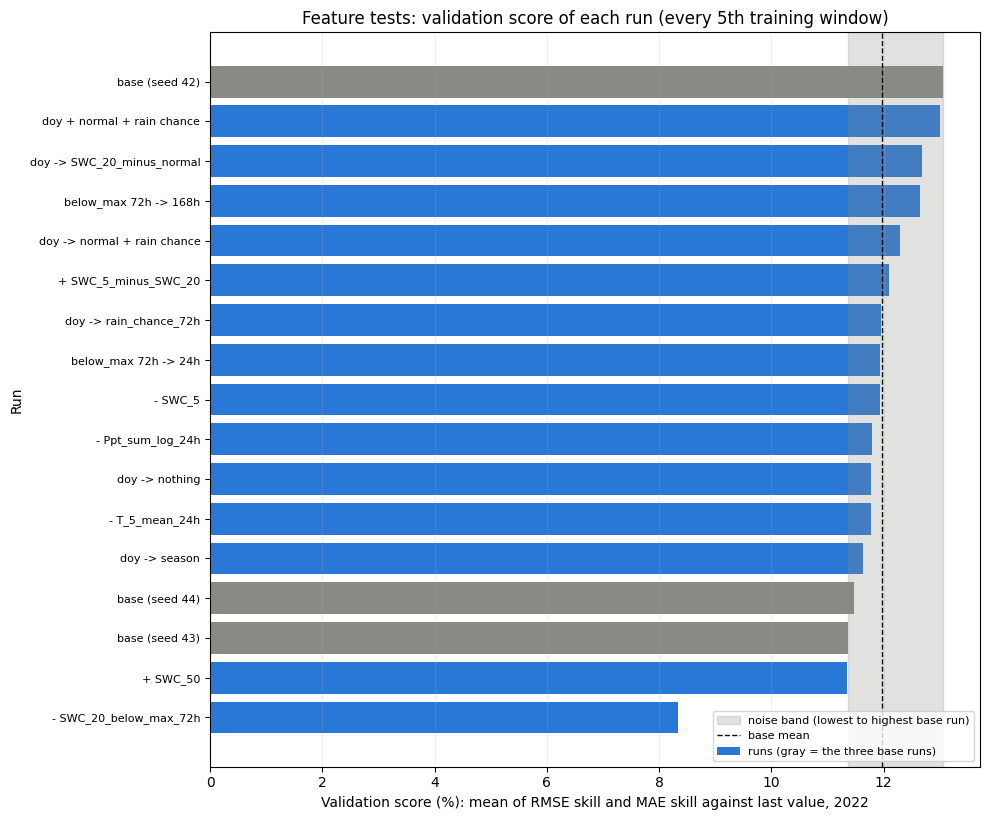

In [21]:
order = summary.index[::-1]                                # best run at the top
fig, ax = plt.subplots(figsize=(10, 0.4 * len(order) + 1.5))
ax.barh(np.arange(len(order)), summary.loc[order, "val_score"] * 100,
        color=[C_MUTED if summary.loc[n, "group"] == "base" else C_MODEL for n in order],
        label="runs (gray = the three base runs)")
ax.axvspan(min(base_scores) * 100, max(base_scores) * 100, color=C_MUTED, alpha=0.25,
           label="noise band (lowest to highest base run)")
ax.axvline(np.mean(base_scores) * 100, color=C_ACTUAL, linestyle="--", linewidth=1, label="base mean")
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels(order, fontsize=8)
ax.set_xlabel("Validation score (%): mean of RMSE skill and MAE skill against last value, 2022")
ax.set_ylabel("Run")
ax.set_title(f"Feature tests: validation score of each run (every {SCREEN_STRIDE}th training window)")
ax.grid(axis="x", alpha=0.3, linewidth=0.5)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 10. Feature choice

Prints the best run, how each seasonality option compares with doy sin/cos, and the inputs used in parts 2 and 3 (`final_features`).

In [22]:
ranked = summary["val_score"]
print(f"Best run on validation: {ranked.index[0]} ({ranked.iloc[0]:+.2%}); runner-up: {ranked.index[1]} "
      f"({ranked.iloc[1]:+.2%}).")
print(f"Base runs (seeds {', '.join(map(str, BASE_SEEDS))}): {', '.join(f'{s:+.2%}' for s in base_scores)}; "
      f"seed spread (noise floor) {noise_floor:.2%}.")

print("\nSeasonality options against doy sin/cos (the base mean):")
seasonal = summary[summary["group"] == "seasonality"]
for name, row in seasonal.iterrows():
    print(f"  {name}: {row['val_score']:+.2%} ({row['diff_vs_base']:+.2%})")
best_seasonal = seasonal.index[0]
if seasonal.loc[best_seasonal, "val_score"] > max(base_scores):
    print(f"Best seasonality option: {best_seasonal}, {seasonal.loc[best_seasonal, 'diff_vs_base']:+.2%} against "
          f"doy sin/cos and above all three base runs.")
else:
    print("No seasonality option beat all three base runs, so doy sin/cos stays.")

beat_all = summary[summary["val_score"] > max(base_scores)]
if len(beat_all):
    chosen = beat_all.index[0]
    final_features = next(r["features"] for r in all_runs if r["name"] == chosen)
else:
    chosen, final_features = "base", BASE
print(f"\nInputs to use: {chosen} (the best run that beat all three base runs; the base if none did).")
print("Used in parts 2 and 3 (paste this at the start of section 11 if you restart from there):")
print(f"FEATURES = {final_features!r}")
save_choice("FEATURES", final_features)

Best run on validation: base (seed 42) (+13.06%); runner-up: doy + normal + rain chance (+13.01%).
Base runs (seeds 42, 43, 44): +13.06%, +11.36%, +11.48%; seed spread (noise floor) 1.70%.

Seasonality options against doy sin/cos (the base mean):
  doy + normal + rain chance: +13.01% (+1.04%)
  doy -> SWC_20_minus_normal: +12.68% (+0.71%)
  doy -> normal + rain chance: +12.29% (+0.32%)
  doy -> rain_chance_72h: +11.95% (-0.02%)
  doy -> nothing: +11.77% (-0.19%)
  doy -> season: +11.64% (-0.33%)
No seasonality option beat all three base runs, so doy sin/cos stays.

Inputs to use: base (the best run that beat all three base runs; the base if none did).
Used in parts 2 and 3 (paste this at the start of section 11 if you restart from there):
FEATURES = ['SWC_20', 'Ppt_sum_log_24h', 'T_5_mean_24h', 'doy_sin', 'doy_cos', 'SWC_5', 'SWC_20_below_max_72h']
saved FEATURES to /content/drive/MyDrive/three_stations_72h/choices.json


## 11. Part 2: loss tests

Huber with a small δ aims at the typical outcome, which is slow drying, so it is good for MAE but too dry when rain comes. MSE aims at the average outcome, including the jumps after rain, so it is usually better for RMSE. A larger δ sits between the two.

The inputs used from here on and what each one tells the model. `FEATURES = None` uses the inputs chosen in part 1; a pasted list is used as it is.

In [23]:
FEATURES = None    # None = the inputs chosen in part 1 (final_features); or paste a list here
if FEATURES is None:
    FEATURES = final_features
assert set(FEATURES) <= set(ALL_FEATURES) and TARGET in FEATURES, "FEATURES must come from ALL_FEATURES and include SWC_20"
for col in FEATURES:
    print(f"{col}: {FEATURE_NOTES[col]}")

SWC_20: soil water at 20 cm now; the forecast starts from this value
Ppt_sum_log_24h: log1p of the rain in the last 24 h; recent rain may still be soaking down
T_5_mean_24h: mean soil temperature at 5 cm over the last 24 h; warm soil loses water faster to evaporation and plants
doy_sin: day of year as a point on a circle, with doy_cos; drying speed and rain change through the year
doy_cos: day of year as a point on a circle, with doy_sin; 31 Dec and 1 Jan end up close together
SWC_5: soil water at 5 cm; it reacts to rain first, so it shows water that may still reach 20 cm
SWC_20_below_max_72h: SWC_20 minus its highest value in the last 72 h (always <= 0); 0 = at its recent peak, slightly negative = it has started drying, very negative = it has been drying for days


Trains each loss with seeds 42 and 43, about 3 minutes per run.

In [24]:
loss_runs = []
for loss_name in LOSS_OPTIONS:
    for seed in LOSS_SEEDS:
        loss_runs.append(run(f"{loss_name} (seed {seed})", FEATURES, loss_name, SCREEN_STRIDE, seed=seed))

Huber 0.005 (seed 42): 17 epochs run, best epoch 7, 110 s, validation score +13.06%
Huber 0.005 (seed 43): 15 epochs run, best epoch 5, 98 s, validation score +11.36%
Huber 0.01 (seed 42): 17 epochs run, best epoch 7, 114 s, validation score +12.80%
Huber 0.01 (seed 43): 16 epochs run, best epoch 6, 107 s, validation score +12.28%
Huber 0.02 (seed 42): 21 epochs run, best epoch 11, 141 s, validation score +11.88%
Huber 0.02 (seed 43): 12 epochs run, best epoch 2, 81 s, validation score +11.19%
MSE (seed 42): 16 epochs run, best epoch 6, 105 s, validation score -3.17%
MSE (seed 43): 15 epochs run, best epoch 5, 99 s, validation score -10.79%


## 12. Loss test results

One row per run, then the mean of the two seeds for each loss, sorted by validation score. `seed_spread` is the gap between the two seeds' validation scores.

In [25]:
per_run = pd.DataFrame([{"run": r["name"], "loss": r["loss"], "seed": r["seed"], **summary_row(r)}
                        for r in loss_runs]).set_index("run")
show(per_run, "loss_per_run")

by_loss = per_run.drop(columns="seed").groupby("loss", sort=False).mean(numeric_only=True)
by_loss.insert(1, "seed_spread", per_run.groupby("loss", sort=False)["val_score"].agg(lambda s: s.max() - s.min()))
by_loss = by_loss.sort_values("val_score", ascending=False)
show(by_loss, "loss_by_loss")

,loss,seed,val_score,val_RMSE_skill,val_MAE_skill,test_RMSE_skill,test_MAE_skill,val_bias,test_bias,test_change_corr,test_lag_hours,best_epoch,epochs_run,seconds
run,,,,,,,,,,,,,,
Huber 0.005 (seed 42),Huber 0.005,42,+13.1%,+5.9%,+20.2%,+3.0%,+24.7%,-0.00217,-0.00435,0.280,63.0,7,17,110.1
Huber 0.005 (seed 43),Huber 0.005,43,+11.4%,+4.7%,+18.0%,+3.0%,+23.8%,-0.00288,-0.00420,0.293,63.3,5,15,97.8
Huber 0.01 (seed 42),Huber 0.01,42,+12.8%,+6.0%,+19.6%,+3.0%,+25.3%,-0.00207,-0.00472,0.290,62.7,7,17,113.8
Huber 0.01 (seed 43),Huber 0.01,43,+12.3%,+5.2%,+19.4%,+3.3%,+25.1%,-0.00241,-0.00417,0.293,63.0,6,16,107.0
Huber 0.02 (seed 42),Huber 0.02,42,+11.9%,+6.1%,+17.6%,+3.8%,+21.7%,-0.00139,-0.00337,0.294,72.0,11,21,141.2
Huber 0.02 (seed 43),Huber 0.02,43,+11.2%,+5.8%,+16.5%,+3.4%,+25.2%,-0.00256,-0.00465,0.300,71.3,2,12,80.7
MSE (seed 42),MSE,42,-3.2%,+3.7%,-10.0%,+5.1%,+3.5%,0.00234,0.00121,0.323,72.0,6,16,105.4
MSE (seed 43),MSE,43,-10.8%,+1.6%,-23.2%,+3.5%,-2.7%,0.00392,0.00226,0.277,71.7,5,15,98.9


,val_score,seed_spread,val_RMSE_skill,val_MAE_skill,test_RMSE_skill,test_MAE_skill,val_bias,test_bias,test_change_corr,test_lag_hours,best_epoch,epochs_run,seconds
loss,,,,,,,,,,,,,
Huber 0.01,+12.5%,0.5%,+5.6%,+19.5%,+3.2%,+25.2%,-0.00224,-0.00445,0.291,62.8,6.5,16.5,110.4
Huber 0.005,+12.2%,1.7%,+5.3%,+19.1%,+3.0%,+24.2%,-0.00253,-0.00427,0.286,63.2,6.0,16.0,104.0
Huber 0.02,+11.5%,0.7%,+6.0%,+17.1%,+3.6%,+23.4%,-0.00198,-0.00401,0.297,71.7,6.5,16.5,110.9
MSE,-7.0%,7.6%,+2.6%,-16.6%,+4.3%,+0.4%,0.00313,0.00173,0.300,71.8,5.5,15.5,102.1


The same runs for each station, on validation and test. The last-value and 24 h moving average rows give the error levels that the skills are measured against.

In [26]:
show(score_table({**baselines(), **{r["name"]: r["pred"] for r in loss_runs}}), "loss_scores_by_station")

RMSE      MAE     bias   CORR RMSE_skill MAE_skill  change_corr  lag_hours
forecast              partition station                                                                               
Last value            val       pooled   0.02010  0.00807 -0.00014  0.960      +0.0%     +0.0%          NaN       72.0
                                FD11     0.03265  0.01640 -0.00037  0.825      +0.0%     +0.0%          NaN       72.0
                                CB25     0.00459  0.00310  0.00018  0.913      +0.0%     +0.0%          NaN       72.0
                                FD02     0.01118  0.00470 -0.00023  0.836      +0.0%     +0.0%          NaN       72.0
24h moving average    val       pooled   0.02103  0.00897 -0.00016  0.956      -4.7%    -11.1%        0.026       83.7
                                FD11     0.03408  0.01807 -0.00042  0.807      -4.4%    -10.2%        0.035       83.0
                                CB25     0.00504  0.00352  0.00022  0.895      -9.9%    -13.4%       -0.134       84.0
                                FD02     0.01186  0.00532 -0.00027  0.814      -6.1%    -13.1%       -0.026       84.0
Huber 0.005 (seed 42) val       pooled   0.01892  0.00644 -0.00217  0.964      +5.9%    +20.2%        0.355       56.0
                                FD11     0.03108  0.01249 -0.00569  0.841      +4.8%    +23.9%        0.372       72.0
                                CB25     0.00433  0.00321 -0.00072  0.924      +5.6%     -3.5%        0.468       72.0
                                FD02     0.00943  0.00361 -0.00011  0.880     +15.6%    +23.2%        0.536       24.0
Huber 0.005 (seed 43) val       pooled   0.01915  0.00661 -0.00288  0.964      +4.7%    +18.0%        0.353       64.0
                                FD11     0.03142  0.01285 -0.00543  0.837      +3.8%    +21.7%        0.371       72.0
                                CB25     0.00452  0.00353 -0.00173  0.927      +1.5%    -13.9%        0.433       72.0
                                FD02     0.00963  0.00346 -0.00147  0.877     +13.8%    +26.4%        0.539       48.0
Huber 0.01 (seed 42)  val       pooled   0.01890  0.00648 -0.00207  0.964      +6.0%    +19.6%        0.356       55.7
                                FD11     0.03109  0.01234 -0.00609  0.842      +4.8%    +24.8%        0.366       71.0
                                CB25     0.00433  0.00320 -0.00040  0.923      +5.6%     -3.3%        0.462       72.0
                                FD02     0.00930  0.00391  0.00028  0.884     +16.8%    +16.8%        0.561       24.0
Huber 0.01 (seed 43)  val       pooled   0.01906  0.00650 -0.00241  0.964      +5.2%    +19.4%        0.343       64.0
                                FD11     0.03129  0.01270 -0.00544  0.838      +4.2%    +22.6%        0.361       72.0
                                CB25     0.00450  0.00336 -0.00109  0.923      +2.0%     -8.3%        0.395       72.0
                                FD02     0.00954  0.00346 -0.00072  0.877     +14.7%    +26.5%        0.526       48.0
Huber 0.02 (seed 42)  val       pooled   0.01887  0.00665 -0.00139  0.964      +6.1%    +17.6%        0.355       64.0
                                FD11     0.03094  0.01309 -0.00463  0.840      +5.2%    +20.2%        0.370       72.0
                                CB25     0.00432  0.00303  0.00024  0.922      +5.8%     +2.3%        0.384       72.0
                                FD02     0.00957  0.00382  0.00021  0.877     +14.4%    +18.6%        0.519       48.0
Huber 0.02 (seed 43)  val       pooled   0.01892  0.00673 -0.00256  0.965      +5.8%    +16.5%        0.372       64.0
                                FD11     0.03096  0.01277 -0.00536  0.840      +5.2%    +22.1%        0.391       72.0
                                CB25     0.00476  0.00387 -0.00168  0.923      -3.7%    -24.7%        0.406       72.0
                                FD02     0.00966  0.00356 -0.00065  0.874     +13.5%    +24.2%        0.541       48.

Skill split by whether at least 2 mm of rain fell in the 72 hours between the window and its target. The model cannot see that rain; the split only shows where each loss gains or loses against last value.

In [27]:
rows = []
for r in loss_runs:
    for part_name in ("val", "test"):
        rows += [{"run": r["name"], "partition": part_name, **row}
                 for row in gap_rain_split(SCORED[part_name], r["pred"][part_name])]
show(pd.DataFrame(rows).set_index(["run", "partition", "windows"]), "loss_gap_rain")

count share_of_windows share_of_last_value_sq_error RMSE_skill MAE_skill     bias  last_value_bias
run                   partition windows                                                                                                                 
Huber 0.005 (seed 42) val       no gap rain (< 2 mm)  21436            82.7%                        15.9%     +41.6%    +32.5%  0.00093          0.00303
                                gap rain (>= 2 mm)     4487            17.3%                        84.1%      +0.6%     +6.1% -0.01703         -0.01532
                      test      no gap rain (< 2 mm)  19160            73.7%                        16.5%     +47.9%    +51.7%  0.00359          0.00915
                                gap rain (>= 2 mm)     6833            26.3%                        83.5%      -3.6%     +0.4% -0.02660         -0.02137
Huber 0.005 (seed 43) val       no gap rain (< 2 mm)  21436            82.7%                        15.9%     +39.0%    +29.4%  0.00027          0.00303
                                gap rain (>= 2 mm)     4487            17.3%                        84.1%      -0.5%     +4.9% -0.01791         -0.01532
                      test      no gap rain (< 2 mm)  19160            73.7%                        16.5%     +44.7%    +48.6%  0.00378          0.00915
                                gap rain (>= 2 mm)     6833            26.3%                        83.5%      -3.2%     +1.4% -0.02657         -0.02137
Huber 0.01 (seed 42)  val       no gap rain (< 2 mm)  21436            82.7%                        15.9%     +40.8%    +31.5%  0.00102          0.00303
                                gap rain (>= 2 mm)     4487            17.3%                        84.1%      +0.8%     +5.9% -0.01683         -0.01532
                      test      no gap rain (< 2 mm)  19160            73.7%                        16.5%     +50.1%    +52.9%  0.00310          0.00915
                                gap rain (>= 2 mm)     6833            26.3%                        83.5%      -3.8%     +0.5% -0.02665         -0.02137
Huber 0.01 (seed 43)  val       no gap rain (< 2 mm)  21436            82.7%                        15.9%     +39.9%    +31.5%  0.00074          0.00303
                                gap rain (>= 2 mm)     4487            17.3%                        84.1%      -0.0%     +5.4% -0.01749         -0.01532
                      test      no gap rain (< 2 mm)  19160            73.7%                        16.5%     +47.4%    +50.8%  0.00375          0.00915
                                gap rain (>= 2 mm)     6833            26.3%                        83.5%      -3.2%     +1.9% -0.02638         -0.02137
Huber 0.02 (seed 42)  val       no gap rain (< 2 mm)  21436            82.7%                        15.9%     +36.3%    +27.9%  0.00172          0.00303
                                gap rain (>= 2 mm)     4487            17.3%                        84.1%      +1.5%     +5.8% -0.01625         -0.01532
                      test      no gap rain (< 2 mm)  19160            73.7%                        16.5%     +44.4%    +44.0%  0.00464          0.00915
                                gap rain (>= 2 mm)     6833            26.3%                        83.5%      -2.3%     +1.5% -0.02583         -0.02137
Huber 0.02 (seed 43)  val       no gap rain (< 2 mm)  21436            82.7%                        15.9%     +38.9%    +26.5%  0.00053          0.00303
                                gap rain (>= 2 mm)     4487            17.3%                        84.1%      +0.8%     +5.1% -0.01734         -0.01532
                      test      no gap rain (< 2 mm)  19160            73.7%                        16.5%     +47.7%    +52.0%  0.00321          0.00915
                                gap rain (>= 2 mm)     6833            26.3%                        83.5%      -3.1%     +1.1% -0.02670         -0.02137
MSE (seed 42)         val       no gap rain (< 2 mm)  21436            82.7%

## 13. Loss choice

Prints the best loss, the runner-up and the seed spread. The best loss (`best_loss`) is used in part 3.

In [28]:
best, runner_up = by_loss.index[0], by_loss.index[1]
for label, name in (("Best loss", best), ("Runner-up", runner_up)):
    row = by_loss.loc[name]
    print(f"{label} on validation (mean of seeds {LOSS_SEEDS}): {name}, score {row['val_score']:+.2%}, RMSE skill "
          f"{row['val_RMSE_skill']:+.1%}, MAE skill {row['val_MAE_skill']:+.1%}, bias {row['val_bias']:+.5f}")
print(f"Seed spread of the validation score: {by_loss['seed_spread'].min():.2%} to {by_loss['seed_spread'].max():.2%}; "
      f"the best loss is {by_loss.loc[best, 'val_score'] - by_loss.loc[runner_up, 'val_score']:.2%} ahead of the "
      f"runner-up.")
best_loss = best
print("Used in part 3 (paste this at the start of section 14 if you restart from there):")
print(f"LOSS = {best_loss!r}")
save_choice("LOSS", best_loss)

Best loss on validation (mean of seeds [42, 43]): Huber 0.01, score +12.54%, RMSE skill +5.6%, MAE skill +19.5%, bias -0.00224
Runner-up on validation (mean of seeds [42, 43]): Huber 0.005, score +12.21%, RMSE skill +5.3%, MAE skill +19.1%, bias -0.00253
Seed spread of the validation score: 0.52% to 7.63%; the best loss is 0.32% ahead of the runner-up.
Used in part 3 (paste this at the start of section 14 if you restart from there):
LOSS = 'Huber 0.01'
saved LOSS to /content/drive/MyDrive/three_stations_72h/choices.json


## 14. Part 3: final model

Sets the loss of the final models and lists the inputs of the previous model. `LOSS = None` uses the loss chosen in part 2; a pasted value such as `"Huber 0.005"` is used as it is. The new model uses `FEATURES` from section 11, and the previous model uses the 7 inputs of combined_10yr.

In [29]:
LOSS = None    # None = the loss chosen in part 2 (best_loss); or paste e.g. "Huber 0.005"
if LOSS is None:
    LOSS = best_loss
assert LOSS in LOSS_OPTIONS, f"LOSS must be one of {list(LOSS_OPTIONS)}"
print("new model inputs:", FEATURES)
print("new model loss:", LOSS)
print("previous model inputs:", PREVIOUS_FEATURES)

new model inputs: ['SWC_20', 'Ppt_sum_log_24h', 'T_5_mean_24h', 'doy_sin', 'doy_cos', 'SWC_5', 'SWC_20_below_max_72h']
new model loss: Huber 0.01
previous model inputs: ['SWC_20', 'Ppt_sum_log_24h', 'T_5_mean_24h', 'doy_sin', 'doy_cos', 'SWC_5', 'SWC_20_below_max_72h']


Trains the previous setup (combined_10yr's 7 inputs, Huber δ 0.005) and the new setup (`FEATURES` and `LOSS`) with the default BiLSTM on every training window, about 10–15 minutes each. If `FEATURES` and `LOSS` are still the defaults, the two are the same and the model is trained once.

In [30]:
previous = run("previous model", PREVIOUS_FEATURES, "Huber 0.005", FULL_STRIDE)
if FEATURES == PREVIOUS_FEATURES and LOSS == "Huber 0.005":
    new = previous
    print("FEATURES and LOSS are still the defaults, so the new model is the previous model.")
else:
    new = run("new model", FEATURES, LOSS, FULL_STRIDE)

previous model: 12 epochs run, best epoch 2, 379 s, validation score +10.16%
new model: 12 epochs run, best epoch 2, 376 s, validation score +12.92%


Training and validation loss per epoch; epoch 0 is the untrained model, and the dotted line marks the epoch whose weights were kept. Each run has its own y-axis.

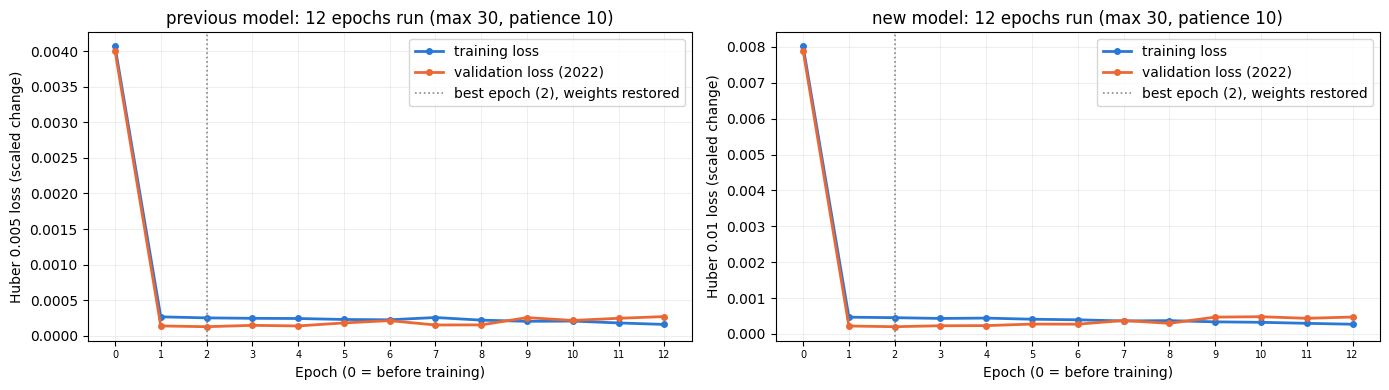

In [31]:
def plot_losses(results):
    """Training and validation loss per epoch, one panel per run."""
    fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 4), squeeze=False)
    for ax, r in zip(axes.flat, results):
        epochs_axis = np.arange(len(r["history"]["train"]))
        ax.plot(epochs_axis, r["history"]["train"], color=C_MODEL, linewidth=2, marker="o", markersize=4,
                label="training loss")
        ax.plot(epochs_axis, r["history"]["val"], color=C_LAST, linewidth=2, marker="o", markersize=4,
                label="validation loss (2022)")
        ax.axvline(r["best_epoch"], color=C_MUTED, linestyle=":", linewidth=1.2,
                   label=f"best epoch ({r['best_epoch']}), weights restored")
        ax.set_xticks(epochs_axis)
        ax.tick_params(axis="x", labelsize=7)
        ax.set_xlabel("Epoch (0 = before training)")
        ax.set_ylabel(f"{r['loss']} loss (scaled change)")
        ax.set_title(f"{r['name']}: {r['epochs_run']} epochs run (max {EPOCHS}, patience {PATIENCE})")
        ax.grid(alpha=0.3, linewidth=0.5)
        ax.legend()
    plt.tight_layout()
    plt.show()


plot_losses([previous] if new is previous else [previous, new])

Scores of both models next to last value and the 24 h moving average, pooled and per station, for validation and test.

In [32]:
show(score_table({**baselines(), "previous model": previous["pred"], "new model": new["pred"]}), "final_scores_previous_new")

RMSE      MAE     bias   CORR RMSE_skill MAE_skill  change_corr  lag_hours
forecast           partition station                                                                               
Last value         val       pooled   0.02010  0.00807 -0.00014  0.960      +0.0%     +0.0%          NaN       72.0
                             FD11     0.03265  0.01640 -0.00037  0.825      +0.0%     +0.0%          NaN       72.0
                             CB25     0.00459  0.00310  0.00018  0.913      +0.0%     +0.0%          NaN       72.0
                             FD02     0.01118  0.00470 -0.00023  0.836      +0.0%     +0.0%          NaN       72.0
24h moving average val       pooled   0.02103  0.00897 -0.00016  0.956      -4.7%    -11.1%        0.026       83.7
                             FD11     0.03408  0.01807 -0.00042  0.807      -4.4%    -10.2%        0.035       83.0
                             CB25     0.00504  0.00352  0.00022  0.895      -9.9%    -13.4%       -0.134       84.0
                             FD02     0.01186  0.00532 -0.00027  0.814      -6.1%    -13.1%       -0.026       84.0
previous model     val       pooled   0.01931  0.00675 -0.00286  0.963      +3.9%    +16.4%        0.328       48.0
                             FD11     0.03133  0.01227 -0.00679  0.840      +4.0%    +25.2%        0.367       72.0
                             CB25     0.00533  0.00368 -0.00145  0.892     -16.2%    -18.8%        0.437       48.0
                             FD02     0.01041  0.00429 -0.00035  0.858      +6.9%     +8.7%        0.527       24.0
new model          val       pooled   0.01903  0.00641 -0.00288  0.964      +5.3%    +20.5%        0.352       63.7
                             FD11     0.03132  0.01261 -0.00644  0.839      +4.1%    +23.1%        0.353       72.0
                             CB25     0.00433  0.00324 -0.00117  0.928      +5.6%     -4.4%        0.437       72.0
                             FD02     0.00931  0.00339 -0.00102  0.884     +16.7%    +27.9%        0.565       47.0
Last value         test      pooled   0.03012  0.01541  0.00113  0.938      +0.0%     +0.0%          NaN       72.0
                             FD11     0.03345  0.01775  0.00142  0.868      +0.0%     +0.0%          NaN       72.0
                             CB25     0.03809  0.02227  0.00118  0.806      +0.0%     +0.0%          NaN       72.0
                             FD02     0.01231  0.00621  0.00078  0.897      +0.0%     +0.0%          NaN       72.0
24h moving average test      pooled   0.03112  0.01677  0.00129  0.933      -3.3%     -8.8%        0.091       83.7
                             FD11     0.03445  0.01922  0.00164  0.858      -3.0%     -8.2%        0.096       83.0
                             CB25     0.03935  0.02415  0.00135  0.789      -3.3%     -8.4%        0.097       84.0
                             FD02     0.01301  0.00695  0.00086  0.884      -5.7%    -11.9%       -0.005       84.0
previous model     test      pooled   0.02925  0.01137 -0.00532  0.941      +2.9%    +26.2%        0.295       55.3
                             FD11     0.03207  0.01289 -0.00582  0.875      +4.1%    +27.4%        0.331       50.0
                             CB25     0.03761  0.01662 -0.00846  0.808      +1.2%    +25.4%        0.278       68.0
                             FD02     0.01110  0.00459 -0.00167  0.913      +9.8%    +26.0%        0.461       48.0
new model          test      pooled   0.02928  0.01135 -0.00543  0.941      +2.8%    +26.4%        0.294       63.0
                             FD11     0.03216  0.01269 -0.00663  0.875      +3.9%    +28.5%        0.337       71.0
                             CB25     0.03763  0.01684 -0.00826  0.807      +1.2%    +24.4%        0.266       70.0
                             FD02     0.01104  0.00452 -0.00140  0.914     +10.4%    +27.2%        0.455       48.0

## 15. Grid search

One grid search over the BiLSTM size, using `FEATURES` and `LOSS`: hidden size 32, 64 or 128, 1 to 3 layers, and dropout 0.2 or 0.4, 18 configs in all. Each config is trained on every 5th training window, 2 to 5 minutes each, and compared by validation score.

In [33]:
grid_runs = []
for hidden_size in GRID["hidden_size"]:
    for num_layers in GRID["num_layers"]:
        for dropout in GRID["dropout"]:
            config = {"hidden_size": hidden_size, "num_layers": num_layers, "dropout": dropout}
            grid_runs.append(run(f"hidden {hidden_size}, layers {num_layers}, dropout {dropout}", FEATURES, LOSS,
                                 SCREEN_STRIDE, **config))
            grid_runs[-1]["config"] = config

hidden 32, layers 1, dropout 0.2: 17 epochs run, best epoch 7, 81 s, validation score +10.87%
hidden 32, layers 1, dropout 0.4: 30 epochs run, best epoch 20, 143 s, validation score +12.63%
hidden 32, layers 2, dropout 0.2: 20 epochs run, best epoch 10, 124 s, validation score +12.60%
hidden 32, layers 2, dropout 0.4: 25 epochs run, best epoch 15, 154 s, validation score +12.60%
hidden 32, layers 3, dropout 0.2: 14 epochs run, best epoch 4, 106 s, validation score +11.68%
hidden 32, layers 3, dropout 0.4: 19 epochs run, best epoch 9, 143 s, validation score +12.36%
hidden 64, layers 1, dropout 0.2: 14 epochs run, best epoch 4, 70 s, validation score +12.39%
hidden 64, layers 1, dropout 0.4: 25 epochs run, best epoch 15, 124 s, validation score +12.90%
hidden 64, layers 2, dropout 0.2: 17 epochs run, best epoch 7, 110 s, validation score +12.80%
hidden 64, layers 2, dropout 0.4: 17 epochs run, best epoch 7, 111 s, validation score +11.39%
hidden 64, layers 3, dropout 0.2: 13 epochs run,

The grid sorted by validation score. `default` marks the size used so far (hidden size 64, 2 layers, dropout 0.2).

In [34]:
grid_table = pd.DataFrame([{"config": r["name"], **r["config"], "parameters": n_parameters(r["model"]),
                            "default": r["config"] == DEFAULT_MODEL, **summary_row(r)} for r in grid_runs])
grid_table = grid_table.set_index("config").sort_values("val_score", ascending=False)
show(grid_table, "final_grid")

,hidden_size,num_layers,dropout,parameters,default,val_score,val_RMSE_skill,val_MAE_skill,test_RMSE_skill,test_MAE_skill,val_bias,test_bias,test_change_corr,test_lag_hours,best_epoch,epochs_run,seconds
config,,,,,,,,,,,,,,,,,
"hidden 64, layers 1, dropout 0.4",64,1,0.4,71489,False,+12.9%,+6.3%,+19.5%,+2.8%,+23.0%,-0.00169,-0.00400,0.270,71.3,15,25,124.1
"hidden 64, layers 2, dropout 0.2",64,2,0.2,170817,True,+12.8%,+6.0%,+19.6%,+3.0%,+25.3%,-0.00207,-0.00472,0.290,62.7,7,17,110.3
"hidden 32, layers 1, dropout 0.4",32,1,0.4,19393,False,+12.6%,+5.5%,+19.7%,+3.4%,+23.6%,-0.00224,-0.00397,0.291,62.7,20,30,143.4
"hidden 32, layers 2, dropout 0.4",32,2,0.4,44481,False,+12.6%,+6.0%,+19.2%,+3.7%,+23.6%,-0.00191,-0.00378,0.295,70.7,15,25,154.0
"hidden 32, layers 2, dropout 0.2",32,2,0.2,44481,False,+12.6%,+4.7%,+20.5%,+2.3%,+27.5%,-0.00325,-0.00557,0.282,63.3,10,20,124.1
"hidden 64, layers 1, dropout 0.2",64,1,0.2,71489,False,+12.4%,+6.5%,+18.3%,+3.4%,+23.9%,-0.00189,-0.00389,0.287,63.0,4,14,70.5
"hidden 128, layers 1, dropout 0.2",128,1,0.2,273985,False,+12.4%,+5.0%,+19.8%,+3.2%,+25.0%,-0.00272,-0.00451,0.295,70.0,10,20,117.9
"hidden 32, layers 3, dropout 0.4",32,3,0.4,69569,False,+12.4%,+5.7%,+19.0%,+2.7%,+23.8%,-0.00238,-0.00405,0.264,71.7,9,19,142.8
"hidden 32, layers 3, dropout 0.2",32,3,0.2,69569,False,+11.7%,+5.4%,+17.9%,+3.0%,+22.2%,-0.00198,-0.00343,0.271,71.3,4,14,105.6


## 16. Tuned model

Retrains the best grid config on every training window. If the best config is the default, the new model is reused instead.

best grid config: {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.4}
saved best_grid_config to /content/drive/MyDrive/three_stations_72h/choices.json
tuned model: 11 epochs run, best epoch 1, 260 s, validation score +10.40%


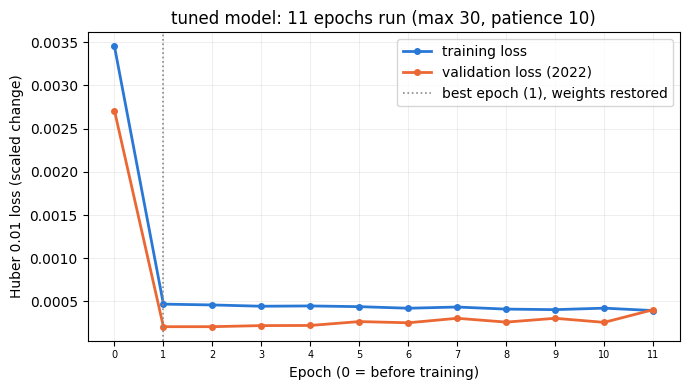

In [35]:
best_config = max(grid_runs, key=lambda r: r["val_score"])["config"]
print("best grid config:", best_config)
save_choice("best_grid_config", best_config)
if best_config == DEFAULT_MODEL:
    tuned = new
    print("It is the default BiLSTM, so the new model is reused as the tuned model.")
else:
    tuned = run("tuned model", FEATURES, LOSS, FULL_STRIDE, **best_config)
    plot_losses([tuned])

## 17. Evaluation

All models on the three training stations, pooled and per station, for validation and test.

In [36]:
models = {"previous model": previous, "new model": new, "tuned model": tuned}
model_sizes = {"previous model": DEFAULT_MODEL, "new model": DEFAULT_MODEL, "tuned model": best_config}
show(score_table({**baselines(), **{name: r["pred"] for name, r in models.items()}}), "final_scores_all_models")

RMSE      MAE     bias   CORR RMSE_skill MAE_skill  change_corr  lag_hours
forecast           partition station                                                                               
Last value         val       pooled   0.02010  0.00807 -0.00014  0.960      +0.0%     +0.0%          NaN       72.0
                             FD11     0.03265  0.01640 -0.00037  0.825      +0.0%     +0.0%          NaN       72.0
                             CB25     0.00459  0.00310  0.00018  0.913      +0.0%     +0.0%          NaN       72.0
                             FD02     0.01118  0.00470 -0.00023  0.836      +0.0%     +0.0%          NaN       72.0
24h moving average val       pooled   0.02103  0.00897 -0.00016  0.956      -4.7%    -11.1%        0.026       83.7
                             FD11     0.03408  0.01807 -0.00042  0.807      -4.4%    -10.2%        0.035       83.0
                             CB25     0.00504  0.00352  0.00022  0.895      -9.9%    -13.4%       -0.134       84.0
                             FD02     0.01186  0.00532 -0.00027  0.814      -6.1%    -13.1%       -0.026       84.0
previous model     val       pooled   0.01931  0.00675 -0.00286  0.963      +3.9%    +16.4%        0.328       48.0
                             FD11     0.03133  0.01227 -0.00679  0.840      +4.0%    +25.2%        0.367       72.0
                             CB25     0.00533  0.00368 -0.00145  0.892     -16.2%    -18.8%        0.437       48.0
                             FD02     0.01041  0.00429 -0.00035  0.858      +6.9%     +8.7%        0.527       24.0
new model          val       pooled   0.01903  0.00641 -0.00288  0.964      +5.3%    +20.5%        0.352       63.7
                             FD11     0.03132  0.01261 -0.00644  0.839      +4.1%    +23.1%        0.353       72.0
                             CB25     0.00433  0.00324 -0.00117  0.928      +5.6%     -4.4%        0.437       72.0
                             FD02     0.00931  0.00339 -0.00102  0.884     +16.7%    +27.9%        0.565       47.0
tuned model        val       pooled   0.01912  0.00678 -0.00339  0.964      +4.9%    +16.0%        0.360       63.7
                             FD11     0.03127  0.01254 -0.00643  0.840      +4.2%    +23.5%        0.378       72.0
                             CB25     0.00481  0.00389 -0.00218  0.926      -4.8%    -25.4%        0.424       71.0
                             FD02     0.00980  0.00391 -0.00156  0.874     +12.3%    +16.8%        0.525       48.0
Last value         test      pooled   0.03012  0.01541  0.00113  0.938      +0.0%     +0.0%          NaN       72.0
                             FD11     0.03345  0.01775  0.00142  0.868      +0.0%     +0.0%          NaN       72.0
                             CB25     0.03809  0.02227  0.00118  0.806      +0.0%     +0.0%          NaN       72.0
                             FD02     0.01231  0.00621  0.00078  0.897      +0.0%     +0.0%          NaN       72.0
24h moving average test      pooled   0.03112  0.01677  0.00129  0.933      -3.3%     -8.8%        0.091       83.7
                             FD11     0.03445  0.01922  0.00164  0.858      -3.0%     -8.2%        0.096       83.0
                             CB25     0.03935  0.02415  0.00135  0.789      -3.3%     -8.4%        0.097       84.0
                             FD02     0.01301  0.00695  0.00086  0.884      -5.7%    -11.9%       -0.005       84.0
previous model     test      pooled   0.02925  0.01137 -0.00532  0.941      +2.9%    +26.2%        0.295       55.3
                             FD11     0.03207  0.01289 -0.00582  0.875      +4.1%    +27.4%        0.331       50.0
                             CB25     0.03761  0.01662 -0.00846  0.808      +1.2%    +25.4%        0.278       68.0
                             FD02     0.01110  0.00459 -0.00167  0.913      +9.8%    +26.0%        0.461       48.0
new model          test      pooled   0.02928  0.01135 -0.00543  0.941      +2.8%    +26.4%      

Every metric on the 2024 test windows, pooled over the three training stations and for each station: MSE, RMSE, MAE, MAPE and SMAPE (in %), RSE (squared error relative to the actual series' variance; below 1 is better than forecasting the mean), CORR and bias. Lower is better for all but CORR.

In [37]:
w = SCORED["test"]
test_forecasts = {**baselines(), **{name: r["pred"] for name, r in models.items()}}
rows = []
for st in ["pooled"] + TRAIN_STATIONS:
    m = np.ones(len(w["y_true"]), dtype=bool) if st == "pooled" else w["station"] == st
    for name, preds in test_forecasts.items():
        rows.append({"station": st, "forecast": name, **compute_metrics(w["y_true"][m], preds["test"][m])})
all_metrics = pd.DataFrame(rows).set_index(["station", "forecast"])[METRIC_COLS]
show(all_metrics, "final_test_all_metrics")

MSE     RMSE      MAE     MAPE    SMAPE      RSE   CORR     Bias
station forecast                                                                                
pooled  Last value          0.00091  0.03012  0.01541  5.44785  5.71352  0.12480  0.938  0.00113
        24h moving average  0.00097  0.03112  0.01677  6.00321  6.27079  0.13320  0.933  0.00129
        previous model      0.00086  0.02925  0.01137  3.87615  4.25329  0.11772  0.941 -0.00532
        new model           0.00086  0.02928  0.01135  3.84286  4.22701  0.11793  0.941 -0.00543
        tuned model         0.00086  0.02930  0.01152  3.96905  4.34970  0.11812  0.941 -0.00517
FD11    Last value          0.00112  0.03345  0.01775  5.38568  5.63856  0.26530  0.868  0.00142
        24h moving average  0.00119  0.03445  0.01922  5.88227  6.12589  0.28134  0.858  0.00164
        previous model      0.00103  0.03207  0.01289  3.75645  4.12186  0.24393  0.875 -0.00582
        new model           0.00103  0.03216  0.01269  3.67470  4.05479  0.24518  0.875 -0.00663
        tuned model         0.00104  0.03224  0.01309  3.83331  4.20560  0.24652  0.874 -0.00571
CB25    Last value          0.00145  0.03809  0.02227  7.12854  7.54733  0.39019  0.806  0.00118
        24h moving average  0.00155  0.03935  0.02415  7.80677  8.23688  0.41648  0.789  0.00135
        previous model      0.00141  0.03761  0.01662  5.00016  5.61946  0.38052  0.808 -0.00846
        new model           0.00142  0.03763  0.01684  5.08775  5.70553  0.38074  0.807 -0.00826
        tuned model         0.00141  0.03749  0.01653  4.98351  5.59444  0.37803  0.810 -0.00851
FD02    Last value          0.00015  0.01231  0.00621  3.82933  3.95469  0.21151  0.897  0.00078
        24h moving average  0.00017  0.01301  0.00695  4.32060  4.44962  0.23629  0.884  0.00086
        previous model      0.00012  0.01110  0.00459  2.87184  3.01856  0.17193  0.913 -0.00167
        new model           0.00012  0.01104  0.00452  2.76616  2.92072  0.16997  0.914 -0.00140
        tuned model         0.00013  0.01141  0.00495  3.09033  3.24907  0.18166  0.909 -0.00129

RMSE and MAE against last value on every partition, including the 2015–2021 training windows (every window, stride 1). A skill much higher on training than on validation and test means the model is overfitting the training years; skill that holds across the three means it generalizes.

In [38]:
w_train = pooled_windows(TRAIN_STATIONS, "train", [TARGET])   # every training window (last value and actual)
train_pred, done = {}, {}
for name, r in models.items():
    if id(r) not in done:                                       # the same run can appear under two names
        w_r = pooled_windows(TRAIN_STATIONS, "train", r["features"])
        assert np.array_equal(w_r["target_time"], w_train["target_time"]), "training windows differ"
        done[id(r)] = predict(r["model"], w_r)
        del w_r
    train_pred[name] = done[id(r)]

rows = []
for part_name, w in {"train": w_train, **SCORED}.items():
    for st in ["pooled"] + TRAIN_STATIONS:
        m = np.ones(len(w["y_true"]), dtype=bool) if st == "pooled" else w["station"] == st
        lv = compute_metrics(w["y_true"][m], w["last"][m])
        for name, r in models.items():
            pred = train_pred[name] if part_name == "train" else r["pred"][part_name]
            mod = compute_metrics(w["y_true"][m], pred[m])
            rows.append({"partition": part_name, "station": st, "model": name,
                         "model_RMSE": mod["RMSE"], "last_value_RMSE": lv["RMSE"], "RMSE_skill": 1 - mod["RMSE"] / lv["RMSE"],
                         "model_MAE": mod["MAE"], "last_value_MAE": lv["MAE"], "MAE_skill": 1 - mod["MAE"] / lv["MAE"],
                         "model_bias": mod["Bias"], "n_targets": int(m.sum())})
persistence = pd.DataFrame(rows).set_index(["partition", "station", "model"])
show(persistence, "final_persistence_check")

model_RMSE  last_value_RMSE RMSE_skill  model_MAE  last_value_MAE MAE_skill  model_bias  n_targets
partition station model                                                                                                             
train     pooled  previous model     0.03066          0.03188      +3.8%    0.01172         0.01575    +25.6%    -0.00733     183735
                  new model          0.03075          0.03188      +3.5%    0.01188         0.01575    +24.6%    -0.00727     183735
                  tuned model        0.03110          0.03188      +2.5%    0.01231         0.01575    +21.8%    -0.00709     183735
          FD11    previous model     0.03507          0.03607      +2.8%    0.01414         0.01889    +25.1%    -0.00950      61245
                  new model          0.03517          0.03607      +2.5%    0.01427         0.01889    +24.5%    -0.00945      61245
                  tuned model        0.03552          0.03607      +1.5%    0.01465         0.01889    +22.4%    -0.00913      61245
          CB25    previous model     0.03366          0.03492      +3.6%    0.01243         0.01668    +25.5%    -0.00734      61246
                  new model          0.03369          0.03492      +3.5%    0.01252         0.01668    +25.0%    -0.00735      61246
                  tuned model        0.03404          0.03492      +2.5%    0.01304         0.01668    +21.9%    -0.00736      61246
          FD02    previous model     0.02137          0.02300      +7.1%    0.00860         0.01169    +26.5%    -0.00516      61244
                  new model          0.02156          0.02300      +6.2%    0.00887         0.01169    +24.2%    -0.00501      61244
                  tuned model        0.02193          0.02300      +4.7%    0.00925         0.01169    +20.9%    -0.00477      61244
val       pooled  previous model     0.01931          0.02010      +3.9%    0.00675         0.00807    +16.4%    -0.00286      25923
                  new model          0.01903          0.02010      +5.3%    0.00641         0.00807    +20.5%    -0.00288      25923
                  tuned model        0.01912          0.02010      +4.9%    0.00678         0.00807    +16.0%    -0.00339      25923
          FD11    previous model     0.03133          0.03265      +4.0%    0.01227         0.01640    +25.2%    -0.00679       8641
                  new model          0.03132          0.03265      +4.1%    0.01261         0.01640    +23.1%    -0.00644       8641
                  tuned model        0.03127          0.03265      +4.2%    0.01254         0.01640    +23.5%    -0.00643       8641
          CB25    previous model     0.00533          0.00459     -16.2%    0.00368         0.00310    -18.8%    -0.00145       8641
                  new model          0.00433          0.00459      +5.6%    0.00324         0.00310     -4.4%    -0.00117       8641
                  tuned model        0.00481          0.00459      -4.8%    0.00389         0.00310    -25.4%    -0.00218       8641
          FD02    previous model     0.01041          0.01118      +6.9%    0.00429         0.00470     +8.7%    -0.00035       8641
                  new model          0.00931          0.01118     +16.7%    0.00339         0.00470    +27.9%    -0.00102       8641
                  tuned model        0.00980          0.01118     +12.3%    0.00391         0.00470    +16.8%    -0.00156       8641
test      pooled  previous model     0.02925          0.03012      +2.9%    0.01137         0.01541    +26.2%    -0.00532      25993
                  new model          0.02928          0.03012      +2.8%    0.01135         0.01541    +26.4%    -0.00543      25993
                  tuned model        0.02930          0.03012      +2.7%    0.01152         0.01541    +25.2%    -0.00517      25993
          FD11    previous model     0.03207          0.03345      +4.1%    0.01289         0.01775    +27.4%    -0.00582       8665
                  new model          0.03216

The same models on CB06 and CB04 in 2024, two stations never used for training. Their inputs are scaled with their own 2015–2021 rows, and windows with a missing input hour are dropped and counted.

In [39]:
UNION = list(dict.fromkeys(PREVIOUS_FEATURES + FEATURES))   # every input that any of the models uses
w_unseen = pooled_windows(UNSEEN_STATIONS, "test", UNION)
print(f"{', '.join(UNSEEN_STATIONS)}, test 2024: {len(w_unseen['y'])} windows; {w_unseen['incomplete']} windows "
      f"with an observed target were dropped because an input hour is missing")


def predict_from(r, w, cols):
    """Forecasts of run r on windows w built with the inputs `cols` (r's own inputs are picked out)."""
    return predict(r["model"], {**w, "X": w["X"][:, :, [cols.index(c) for c in r["features"]]]})


unseen = {**baselines({"test": w_unseen}),
          **{name: {"test": predict_from(r, w_unseen, UNION)} for name, r in models.items()}}
show(score_table(unseen, {"test": w_unseen}), "final_unseen_stations")

CB06, CB04, test 2024: 16354 windows; 0 windows with an observed target were dropped because an input hour is missing


RMSE      MAE     bias   CORR RMSE_skill MAE_skill  change_corr  lag_hours
forecast           partition station                                                                               
Last value         test      pooled   0.02783  0.01437  0.00112  0.876      +0.0%     +0.0%          NaN       72.0
                             CB06     0.01709  0.00800  0.00132  0.936      +0.0%     +0.0%          NaN       72.0
                             CB04     0.03631  0.02156  0.00090  0.781      +0.0%     +0.0%          NaN       72.0
24h moving average test      pooled   0.02905  0.01563  0.00127  0.864      -4.4%     -8.7%        0.035       84.0
                             CB06     0.01806  0.00889  0.00149  0.928      -5.7%    -11.1%       -0.023       84.0
                             CB04     0.03778  0.02323  0.00103  0.760      -4.0%     -7.8%        0.048       84.0
previous model     test      pooled   0.02667  0.01056 -0.00448  0.882      +4.2%    +26.5%        0.327       59.5
                             CB06     0.01555  0.00580 -0.00071  0.944      +9.0%    +27.5%        0.420       48.0
                             CB04     0.03522  0.01593 -0.00872  0.794      +3.0%    +26.1%        0.351       71.0
new model          test      pooled   0.02685  0.01074 -0.00445  0.880      +3.5%    +25.3%        0.306       71.0
                             CB06     0.01570  0.00616 -0.00045  0.943      +8.1%    +23.0%        0.405       71.0
                             CB04     0.03544  0.01590 -0.00895  0.791      +2.4%    +26.2%        0.329       71.0
tuned model        test      pooled   0.02673  0.01123 -0.00381  0.882      +4.0%    +21.9%        0.310       67.5
                             CB06     0.01583  0.00658 -0.00043  0.943      +7.4%    +17.7%        0.374       71.0
                             CB04     0.03518  0.01647 -0.00763  0.794      +3.1%    +23.6%        0.346       64.0

## 18. Forecast or copy

The first table shows `change_corr`, the lag at each station and the false rises (a forecast rise of more than 0.02 while `SWC_20` rose by less than 0.005). The second splits the skill by rain in the 72-hour gap.

In [40]:
rows, gap_rows = [], []
for part_name in ("val", "test"):
    w = SCORED[part_name]
    for name, pred in [("Last value", w["last"])] + [(n, r["pred"][part_name]) for n, r in models.items()]:
        n_rises, n_false = false_rises(w, pred)
        rows.append({"forecast": name, "partition": part_name, "change_corr": scores(w, pred)["change_corr"],
                     **{f"lag_hours_{st}": lag_hours(w, pred, st) for st in TRAIN_STATIONS},
                     "forecast_rises": n_rises, "false_rises": n_false})
        if name != "Last value":
            gap_rows += [{"forecast": name, "partition": part_name, **row} for row in gap_rain_split(w, pred)]
show(pd.DataFrame(rows).set_index(["forecast", "partition"]), "final_forecast_or_copy")
show(pd.DataFrame(gap_rows).set_index(["forecast", "partition", "windows"]), "final_gap_rain")

,,change_corr,lag_hours_FD11,lag_hours_CB25,lag_hours_FD02,forecast_rises,false_rises
forecast,partition,,,,,,
Last value,val,NaN,72.0,72.0,72.0,0,0
previous model,val,0.328,72.0,48.0,24.0,336,122
new model,val,0.352,72.0,72.0,47.0,142,22
tuned model,val,0.360,72.0,71.0,48.0,0,0
Last value,test,NaN,72.0,72.0,72.0,0,0
previous model,test,0.295,50.0,68.0,48.0,172,77
new model,test,0.294,71.0,70.0,48.0,52,8
tuned model,test,0.287,71.0,71.0,48.0,0,0


count share_of_windows share_of_last_value_sq_error RMSE_skill MAE_skill     bias  last_value_bias
forecast       partition windows                                                                                                                 
previous model val       no gap rain (< 2 mm)  21436            82.7%                        15.9%     +28.9%    +26.6%  0.00017          0.00303
                         gap rain (>= 2 mm)     4487            17.3%                        84.1%      -0.1%     +4.5% -0.01734         -0.01532
new model      val       no gap rain (< 2 mm)  21436            82.7%                        15.9%     +42.3%    +34.0%  0.00025          0.00303
                         gap rain (>= 2 mm)     4487            17.3%                        84.1%      -0.1%     +5.0% -0.01779         -0.01532
tuned model    val       no gap rain (< 2 mm)  21436            82.7%                        15.9%     +40.1%    +26.4% -0.00026          0.00303
                         gap rain (>= 2 mm)     4487            17.3%                        84.1%      -0.4%     +3.9% -0.01832         -0.01532
previous model test      no gap rain (< 2 mm)  19160            73.7%                        16.5%     +52.1%    +55.4%  0.00264          0.00915
                         gap rain (>= 2 mm)     6833            26.3%                        83.5%      -4.1%     +0.0% -0.02764         -0.02137
new model      test      no gap rain (< 2 mm)  19160            73.7%                        16.5%     +53.5%    +55.4%  0.00258          0.00915
                         gap rain (>= 2 mm)     6833            26.3%                        83.5%      -4.4%     +0.2% -0.02788         -0.02137
tuned model    test      no gap rain (< 2 mm)  19160            73.7%                        16.5%     +49.6%    +53.2%  0.00272          0.00915
                         gap rain (>= 2 mm)     6833            26.3%                        83.5%      -4.1%     +0.1% -0.02730         -0.02137

Forecast change against actual change for every test window of the tuned model. Points on the diagonal were forecast exactly; last value would put every point on the zero line.

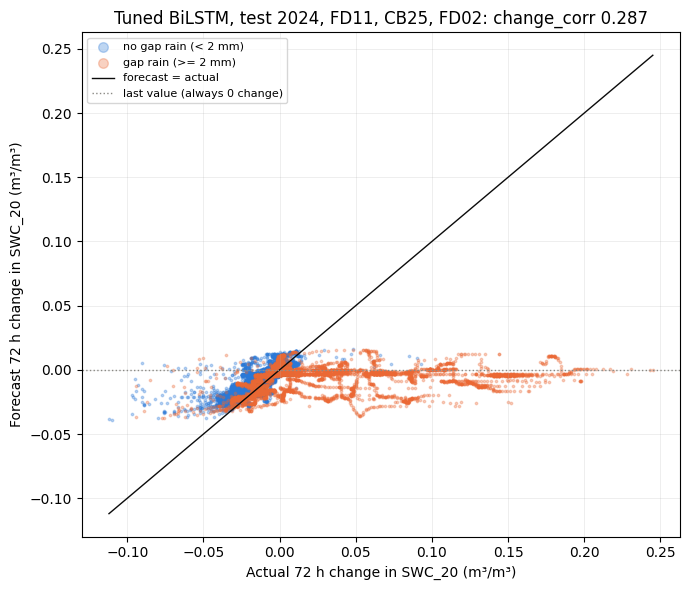

In [41]:
w, pred = SCORED["test"], tuned["pred"]["test"]
actual_change, forecast_change = w["y_true"] - w["last"], pred - w["last"]
rained = w["gap_rain"] >= GAP_RAIN_MM
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(actual_change[~rained], forecast_change[~rained], s=3, alpha=0.3, color=C_MODEL,
           label=f"no gap rain (< {GAP_RAIN_MM:g} mm)")
ax.scatter(actual_change[rained], forecast_change[rained], s=3, alpha=0.3, color=C_LAST,
           label=f"gap rain (>= {GAP_RAIN_MM:g} mm)")
lims = [min(actual_change.min(), forecast_change.min()), max(actual_change.max(), forecast_change.max())]
ax.plot(lims, lims, color=C_ACTUAL, linewidth=1, label="forecast = actual")
ax.axhline(0, color=C_MUTED, linestyle=":", linewidth=1, label="last value (always 0 change)")
ax.set_xlabel("Actual 72 h change in SWC_20 (m³/m³)")
ax.set_ylabel("Forecast 72 h change in SWC_20 (m³/m³)")
ax.set_title(f"Tuned BiLSTM, test 2024, {', '.join(TRAIN_STATIONS)}: change_corr "
             f"{corr(forecast_change, actual_change):.3f}")
ax.grid(alpha=0.3, linewidth=0.5)
ax.legend(markerscale=4, fontsize=8)
plt.tight_layout()
plt.show()

## 19. Plots

The 2024 test year at each training station: actual `SWC_20`, the tuned model and last value, by target time.

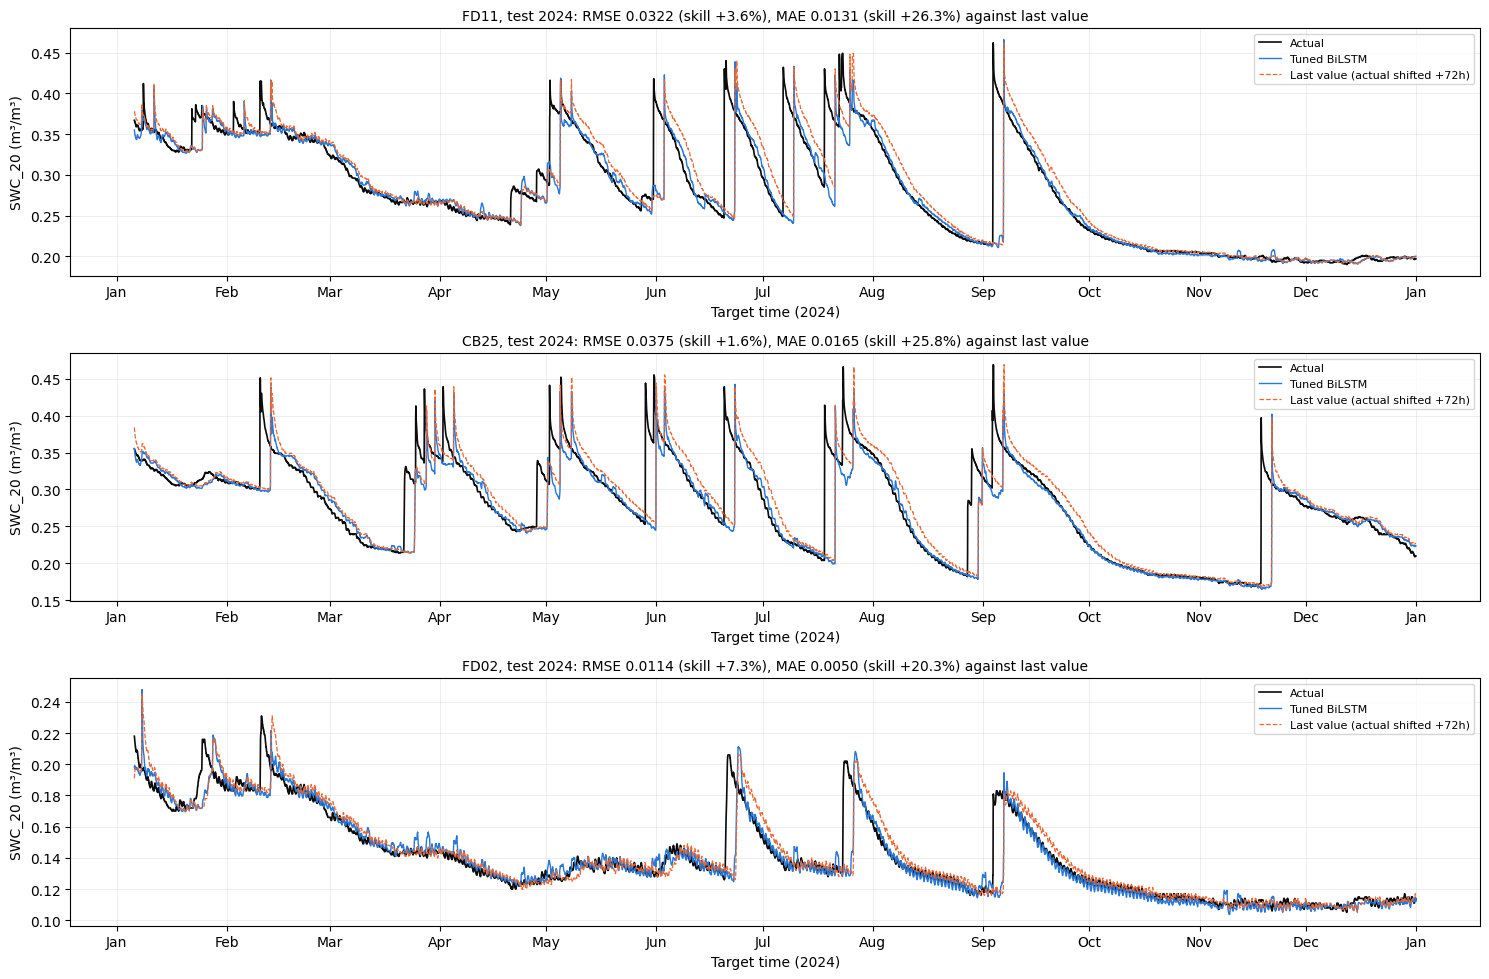

In [42]:
w, pred = SCORED["test"], tuned["pred"]["test"]
fig, axes = plt.subplots(len(TRAIN_STATIONS), 1, figsize=(15, 3.3 * len(TRAIN_STATIONS)), squeeze=False)
for ax, st in zip(axes.flat, TRAIN_STATIONS):
    m = w["station"] == st
    t = pd.DatetimeIndex(w["target_time"][m])
    s = scores(w, pred, m)
    ax.plot(t, w["y_true"][m], color=C_ACTUAL, linewidth=1.2, label="Actual")
    ax.plot(t, pred[m], color=C_MODEL, linewidth=1.0, label="Tuned BiLSTM")
    ax.plot(t, w["last"][m], color=C_LAST, linewidth=0.9, linestyle="--",
            label=f"Last value (actual shifted +{HORIZON}h)")
    ax.set_title(f"{st}, test 2024: RMSE {s['RMSE']:.4f} (skill {s['RMSE_skill']:+.1%}), MAE {s['MAE']:.4f} "
                 f"(skill {s['MAE_skill']:+.1%}) against last value", fontsize=10)
    ax.set_xlabel("Target time (2024)")
    ax.set_ylabel("SWC_20 (m³/m³)")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

FD11 in 2024 by target month, as in combined_10yr, with the monthly scores in the table. Each panel has its own y-axis, and the last-value line is the actual series shifted right by 72 hours.

,model_RMSE,last_value_RMSE,model_MAE,last_value_MAE,model_bias,last_value_bias,model_better_MAE
target month,,,,,,,
2024-01,0.01750,0.01827,0.01204,0.01320,-0.00358,0.00177,True
2024-02,0.01423,0.01569,0.00879,0.01132,-0.00336,0.00206,True
2024-03,0.00687,0.00909,0.00539,0.00695,0.00479,0.00649,True
2024-04,0.01597,0.01540,0.01046,0.00987,-0.00252,-0.00308,False
2024-05,0.03483,0.03669,0.01912,0.02481,-0.01053,-0.00072,True
2024-06,0.05574,0.05975,0.03047,0.04340,-0.01569,-0.00100,True
2024-07,0.06076,0.05713,0.03641,0.04509,-0.02572,-0.00487,True
2024-08,0.00499,0.01620,0.00431,0.01433,0.00395,0.01433,True
2024-09,0.05930,0.06306,0.02299,0.03594,-0.01458,-0.00194,True


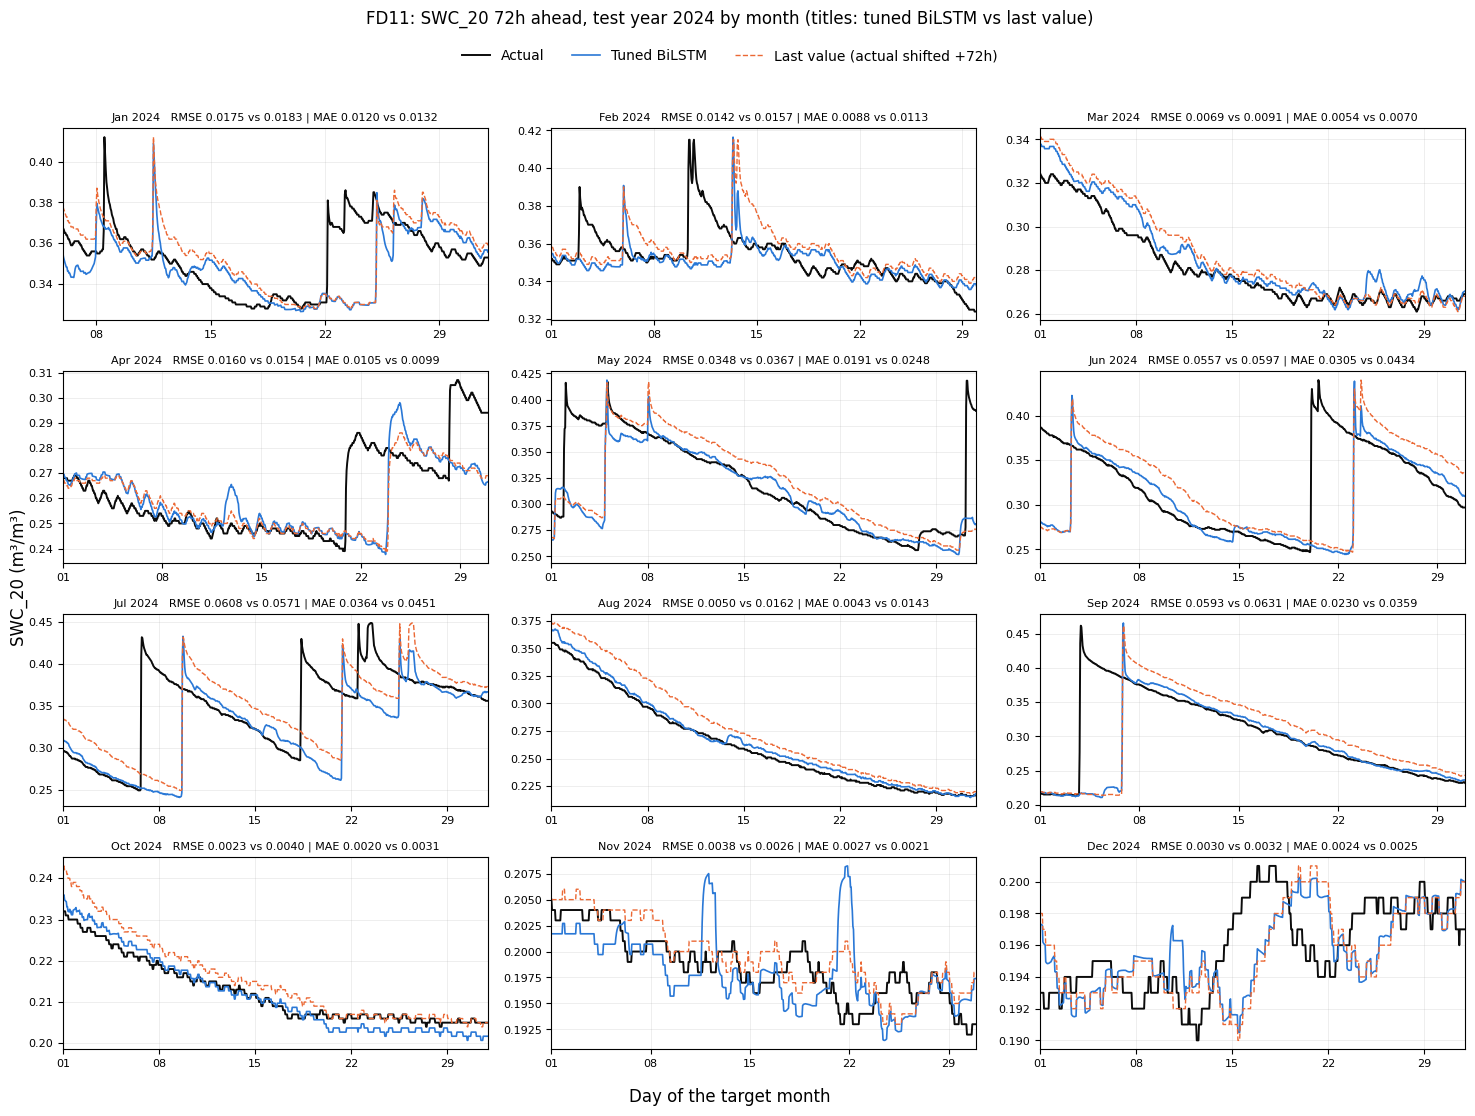

In [43]:
w, pred = SCORED["test"], tuned["pred"]["test"]
m = w["station"] == "FD11"
monthly = pd.DataFrame({"actual": w["y_true"][m], "model": pred[m], "last_value": w["last"][m]},
                       index=pd.DatetimeIndex(w["target_time"][m]))


def month_scores(g):
    mod, last = compute_metrics(g["actual"], g["model"]), compute_metrics(g["actual"], g["last_value"])
    return pd.Series({"model_RMSE": mod["RMSE"], "last_value_RMSE": last["RMSE"], "model_MAE": mod["MAE"],
                      "last_value_MAE": last["MAE"], "model_bias": mod["Bias"], "last_value_bias": last["Bias"]})


by_month = monthly.groupby(monthly.index.to_period("M")).apply(month_scores)
by_month["model_better_MAE"] = by_month["model_MAE"] < by_month["last_value_MAE"]
by_month.index.name = "target month"
show(by_month, "final_fd11_by_month")

months = by_month.index
ncols = 3
nrows = int(np.ceil(len(months) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 2.7 * nrows), squeeze=False)
for ax, month in zip(axes.flat, months):
    g = monthly[monthly.index.to_period("M") == month]
    ax.plot(g.index, g["actual"], color=C_ACTUAL, linewidth=1.4, label="Actual")
    ax.plot(g.index, g["model"], color=C_MODEL, linewidth=1.2, label="Tuned BiLSTM")
    ax.plot(g.index, g["last_value"], color=C_LAST, linewidth=1.0, linestyle="--",
            label=f"Last value (actual shifted +{HORIZON}h)")
    s = by_month.loc[month]
    ax.set_title(f"{month.strftime('%b %Y')}   RMSE {s['model_RMSE']:.4f} vs {s['last_value_RMSE']:.4f} | "
                 f"MAE {s['model_MAE']:.4f} vs {s['last_value_MAE']:.4f}", fontsize=8)
    ax.set_xlim(g.index.min(), g.index.max())
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22, 29]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3, linewidth=0.5)
for ax in axes.flat[len(months):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"FD11: SWC_20 {HORIZON}h ahead, test year 2024 by month (titles: tuned BiLSTM vs last value)", y=1.025)
fig.supxlabel("Day of the target month")
fig.supylabel("SWC_20 (m³/m³)")
plt.tight_layout(rect=(0, 0, 1, 0.975))
plt.show()

## 20. Comparison with older notebooks

FD11 test 2024 scores of the older notebooks, copied from their saved outputs, next to this notebook's FD11 rows.

In [44]:
fd11 = SCORED["test"]["station"] == "FD11"
rows = [
    {"notebook": "akhil_lstm_72h (10/29)", "setup": "FD11, train 2019-21, 24 h window, 11 inputs, 1-layer LSTM",
     "RMSE": 0.03298, "MAE": 0.01369, "RMSE_skill": 0.014, "MAE_skill": 0.230},
    {"notebook": "combined_10yr base", "setup": "FD11, train 2015-21, 48 h window, SWC_20 + Ppt_sum_log_24h",
     "RMSE": 0.03332, "MAE": 0.01390, "RMSE_skill": 0.004, "MAE_skill": 0.217},
    {"notebook": "combined_10yr combined", "setup": "FD11, train 2015-21, 48 h window, the 7 inputs",
     "RMSE": 0.03291, "MAE": 0.01265, "RMSE_skill": 0.016, "MAE_skill": 0.288},
    {"notebook": "last value (48 h windows)", "setup": "", "RMSE": 0.03345, "MAE": 0.01775,
     "RMSE_skill": np.nan, "MAE_skill": np.nan},
]
for name, r in models.items():
    s, size = scores(SCORED["test"], r["pred"]["test"], fd11), model_sizes[name]
    rows.append({"notebook": f"this notebook: {name}",
                 "setup": (f"3 stations, train 2015-21, {len(r['features'])} inputs, {r['loss']}, hidden "
                           f"{size['hidden_size']}, {size['num_layers']} layers, dropout {size['dropout']}"),
                 "RMSE": s["RMSE"], "MAE": s["MAE"], "RMSE_skill": s["RMSE_skill"], "MAE_skill": s["MAE_skill"]})
lv = scores(SCORED["test"], SCORED["test"]["last"], fd11)
rows.append({"notebook": "this notebook: last value", "setup": "same FD11 windows as combined_10yr",
             "RMSE": lv["RMSE"], "MAE": lv["MAE"], "RMSE_skill": np.nan, "MAE_skill": np.nan})
show(pd.DataFrame(rows).set_index("notebook"), "final_comparison_older_notebooks")

,setup,RMSE,MAE,RMSE_skill,MAE_skill
notebook,,,,,
akhil_lstm_72h (10/29),"FD11, train 2019-21, 24 h window, 11 inputs, 1...",0.03298,0.01369,+1.4%,+23.0%
combined_10yr base,"FD11, train 2015-21, 48 h window, SWC_20 + Ppt...",0.03332,0.01390,+0.4%,+21.7%
combined_10yr combined,"FD11, train 2015-21, 48 h window, the 7 inputs",0.03291,0.01265,+1.6%,+28.8%
last value (48 h windows),,0.03345,0.01775,,
this notebook: previous model,"3 stations, train 2015-21, 7 inputs, Huber 0.0...",0.03207,0.01289,+4.1%,+27.4%
this notebook: new model,"3 stations, train 2015-21, 7 inputs, Huber 0.0...",0.03216,0.01269,+3.9%,+28.5%
this notebook: tuned model,"3 stations, train 2015-21, 7 inputs, Huber 0.0...",0.03224,0.01309,+3.6%,+26.3%
this notebook: last value,same FD11 windows as combined_10yr,0.03345,0.01775,,


akhil_lstm_72h's skill is measured against last value on its own 24 h windows (RMSE 0.03345, MAE 0.01779), so its last value differs slightly from the 48 h windows. The test_ppt feature tests and lstm_72_new are left out because they predict a daily mean, not the hourly value.

## 21. Summary

Prints the tuned model's size and its scores against last value (including train / val / test skill), the previous model, the unseen stations and combined_10yr.

In [45]:
w = SCORED["test"]
s_tuned, s_prev = scores(w, tuned["pred"]["test"]), scores(w, previous["pred"]["test"])
s_unseen = scores(w_unseen, unseen["tuned model"]["test"])
s_fd11 = scores(w, tuned["pred"]["test"], fd11)
print(f"Grid search (validation score, one seed each): best {grid_table.index[0]} "
      f"{grid_table['val_score'].iloc[0]:+.2%}, runner-up {grid_table.index[1]} {grid_table['val_score'].iloc[1]:+.2%}")
if grid_table["default"].any():
    print(f"  the default BiLSTM scored {grid_table.loc[grid_table['default'], 'val_score'].iloc[0]:+.2%}; compare "
          f"these gaps with the noise floor printed in section 10")
print(f"Tuned model: hidden size {best_config['hidden_size']}, {best_config['num_layers']} layers, dropout "
      f"{best_config['dropout']}; {len(FEATURES)} inputs; loss {LOSS}.")
print(f"Test 2024, {', '.join(TRAIN_STATIONS)} pooled: RMSE {s_tuned['RMSE']:.5f} (skill {s_tuned['RMSE_skill']:+.1%}), "
      f"MAE {s_tuned['MAE']:.5f} (skill {s_tuned['MAE_skill']:+.1%}), bias {s_tuned['bias']:+.5f}.")
tp = persistence.xs(("pooled", "tuned model"), level=["station", "model"])
print("Tuned model, pooled skill on train / val / test: RMSE "
      + " / ".join(f"{tp.loc[p, 'RMSE_skill']:+.1%}" for p in PARTITIONS) + ", MAE "
      + " / ".join(f"{tp.loc[p, 'MAE_skill']:+.1%}" for p in PARTITIONS) + ".")
print(f"Previous model on the same windows: RMSE skill {s_prev['RMSE_skill']:+.1%}, MAE skill "
      f"{s_prev['MAE_skill']:+.1%}, bias {s_prev['bias']:+.5f}.")
print(f"Unseen stations {', '.join(UNSEEN_STATIONS)}, test 2024: RMSE skill {s_unseen['RMSE_skill']:+.1%}, "
      f"MAE skill {s_unseen['MAE_skill']:+.1%}.")
print(f"FD11, test 2024: RMSE {s_fd11['RMSE']:.5f}, MAE {s_fd11['MAE']:.5f} (combined_10yr combined: 0.03291, "
      f"0.01265).")
print(f"Forecast or copy, test: change_corr {s_tuned['change_corr']:.3f}, mean lag_hours "
      f"{np.mean([lag_hours(w, tuned['pred']['test'], st) for st in TRAIN_STATIONS]):.1f} (last value: {HORIZON}).")

Grid search (validation score, one seed each): best hidden 64, layers 1, dropout 0.4 +12.90%, runner-up hidden 64, layers 2, dropout 0.2 +12.80%
  the default BiLSTM scored +12.80%; compare these gaps with the noise floor printed in section 10
Tuned model: hidden size 64, 1 layers, dropout 0.4; 7 inputs; loss Huber 0.01.
Test 2024, FD11, CB25, FD02 pooled: RMSE 0.02930 (skill +2.7%), MAE 0.01152 (skill +25.2%), bias -0.00517.
Tuned model, pooled skill on train / val / test: RMSE +2.5% / +4.9% / +2.7%, MAE +21.8% / +16.0% / +25.2%.
Previous model on the same windows: RMSE skill +2.9%, MAE skill +26.2%, bias -0.00532.
Unseen stations CB06, CB04, test 2024: RMSE skill +4.0%, MAE skill +21.9%.
FD11, test 2024: RMSE 0.03224, MAE 0.01309 (combined_10yr combined: 0.03291, 0.01265).
Forecast or copy, test: change_corr 0.287, mean lag_hours 63.3 (last value: 72).
